# Order and density shape locust directional alignment in virtual reality

Juvenile desert locusts (*Schistocerca gregaria*) align their heading with the
direction of neighbor motion, a core ingredient of marching behavior. In the virtual-reality experiments of S. Sayin et al., "The behavioral mechanisms governing collective motion in swarming locusts," *Science* **387**(6737), 995-1000 (2025); [doi:10.1126/science.adq7832](https://doi.org/10.1126/science.adq7832), focal locusts walked on a
motion-compensating spherical treadmill surrounded by a panoramic projection
of moving **virtual conspecifics**. The virtual swarm was defined by two
continuous stimulus parameters:

- **order** — the coherence of the virtual motion, 0 = disordered to 1 =
  perfectly aligned (six levels: 0, 0.2, 0.4, 0.6, 0.8, 1.0);
- **density** — the number of virtual locusts per m$^2$ (six levels: 1, 4, 8,
  16, 32, 64).

The biological question: is the focal locust's directional alignment driven
primarily by the directional structure of neighbor motion (order), or does the
number of neighbors (density) matter comparably?


This notebook repeats the individual-level fixed-effect screening and PSIS-LOO sweep, then fits the final step-level hierarchical von Mises model with `brms` and the `unwrap_von_mises` family. The final model has a population mean-direction regression and a concentration random intercept per animal.

The alignment estimand is
$\mathcal{A}(\mathbf{x})=R(\kappa(\mathbf{x}))\cos(\mu(\mathbf{x}))$,
where $R(\kappa)=I_1(\kappa)/I_0(\kappa)$ and $0$ is the virtual march
direction. Density and order vary **between** animals; no animal
experiences multiple stimulus conditions. The raw tracking parts require
approximately 870 MB on first download, followed by rediscretization.


## Setup

Follow the [R setup](../getting-started-r.md) page once, select the
**R (`ir`)** kernel, and run all cells in order. The setup cell checks
that the pinned packages and CmdStan are available; it stops with a
pointer to the setup page if the one-time setup has not been run.
Running the notebook records versions, diagnostics, inline PNGs, and
vector PDFs.


In [1]:
# Setup: check that this notebook's stack is available. The examples
# are verified against the pinned package set recorded in renv.lock, so
# this cell deliberately does not auto-install: an unpinned install
# could silently drift from the verified set. Run the one-time setup on
# the R setup page first (docs/getting-started-r.md).

required <- c("brms", "posterior", "loo", "circular", "ggplot2", "ragg", "arrow")
missing <- required[!vapply(required, requireNamespace, logical(1),
  quietly = TRUE)]
if (length(missing))
  stop("Missing R package(s): ", paste(missing, collapse = ", "),
       " - run the one-time setup on the R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

cmdstan_ok <- tryCatch(
  dir.exists(as.character(cmdstanr::cmdstan_path())),
  error = function(e) FALSE)
if (!cmdstan_ok)
  stop("cmdstanr/CmdStan is not available - run the one-time setup on the",
       " R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

In [2]:
suppressPackageStartupMessages({
    library(brms)
    library(posterior)
    library(loo)
    library(circular)
    library(ggplot2)
    library(arrow)
})

# The repository's R helpers (custom brms family + circular statistics)
# live next to the notebook; make them reachable regardless of the
# kernel's working directory.
repo_root <- if (file.exists(file.path("..", "R", "unwrap_family.R"))) ".." else
    if (file.exists(file.path("R", "unwrap_family.R"))) "." else
    stop("Run this notebook from notebooks_r/ or from the repository root.")
source(file.path(repo_root, "R", "unwrap_family.R"))
source(file.path(repo_root, "R", "unwrap_functions.R"))

# The figure code writes to the repository-relative figures directory.
FIG_DIR <- file.path(repo_root, "figures", "locust_density_order")
dir.create(FIG_DIR, recursive = TRUE, showWarnings = FALSE)
theme_set(theme_minimal(base_size = 12))

# Without X11/cairo (most server R installs) the default device cannot
# rasterise, so each figure renders to a PNG through ragg and displays
# inline; a vector PDF is saved alongside as the portable copy.
show_figure <- function(plot, name, width, height, res = 110) {
  file <- file.path(FIG_DIR, paste0(name, ".png"))
  ragg::agg_png(file, width = width, height = height, units = "in",
                res = res)
  print(plot)
  invisible(dev.off())
  IRdisplay::display_png(file = file)
  invisible(NULL)
}


SEED <- 123
set.seed(SEED)
quick_run <- Sys.getenv("UNWRAP_R_QUICK") == "1"
CHAINS <- 4L
# Hierarchical models need longer adaptation and more retained draws than
# the introductory GLM. Quick mode keeps the full data and model and shortens
# the Monte Carlo plotting/bootstrapping budgets and the screening fits below.
# The final fit keeps its full sampling budget even in quick mode: its
# R-hat/ESS gate needs the ESS the full budget provides (the same convention
# as the mixture notebook).
ITER <- 3000L
WARMUP <- 2000L
ADAPT_DELTA <- 0.97
# The tighter adapt_delta protects the grouped concentration geometry;
# these are execution budgets, not a claim of verified convergence.

c(R = as.character(getRversion()),
  brms = as.character(packageVersion("brms")),
  cmdstanr = as.character(packageVersion("cmdstanr")),
  posterior = as.character(packageVersion("posterior")),
  loo = as.character(packageVersion("loo")),
  circular = as.character(packageVersion("circular")),
  ggplot2 = as.character(packageVersion("ggplot2")),
  ragg = as.character(packageVersion("ragg")),
  arrow = as.character(packageVersion("arrow")))


Loading required package: cmdstanr



This is cmdstanr version 0.9.0



- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr



- CmdStan path: /home/jake/.cmdstan/cmdstan-2.40.0



- CmdStan version: 2.40.0



R          brms      cmdstanr     posterior           loo 
      "4.5.3"      "2.23.0"       "0.9.0"       "1.7.1" "2.10.1.9000" 
     circular       ggplot2          ragg         arrow 
      "0.5.2"       "4.0.3"       "1.5.2"      "26.0.0"

## Figure style

Figures render inline and save vector PDFs under
`figures/locust_density_order/`. All angular calculations use radians and circular summaries.


In [3]:
circ_mean <- function(a) atan2(mean(sin(a)), mean(cos(a)))
resultant <- function(a) Mod(mean(exp(1i * a)))
circ_sd <- function(a, m = circ_mean(a)) {
  sqrt(-2 * log(min(1, Mod(mean(exp(1i * (a - m)))))))
}
# Scaled Bessel functions avoid overflow when concentrations are large.
A1_safe <- function(k) {
  out <- besselI(k, 1, expon.scaled = TRUE) /
    besselI(k, 0, expon.scaled = TRUE)
  if (is.matrix(k)) dim(out) <- dim(k)
  out
}
vm_logpdf <- function(y, mu, kappa) {
  kappa * (cos(y - mu) - 1) - log(2 * pi) -
    log(besselI(kappa, 0, expon.scaled = TRUE))
}
hdi <- function(x, prob = 0.95) {
  x <- sort(as.numeric(x))
  stopifnot(length(x) > 1L, all(is.finite(x)))
  gap <- min(length(x) - 1L, floor(prob * length(x)))
  starts <- seq_len(length(x) - gap)
  j <- starts[which.min(x[starts + gap] - x[starts])]
  c(low = x[j], high = x[j + gap])
}
interval_row <- function(x, angular = FALSE, prob = 0.95) {
  m <- if (angular) circ_mean(x) else mean(x)
  # Unwrap angular intervals around their circular mean before drawing;
  # display endpoints can lie just beyond +/-pi to avoid a false long arc.
  z <- if (angular) m + mod_circular(x - m) else x
  c(mean = m, hdi(z, prob))
}
inverse_A1 <- function(r) {
  if (r <= 0) {
    return(0)
  }
  if (r >= 1) {
    return(Inf)
  }
  upper <- max(2, 1 / (1 - r))
  uniroot(function(k) A1_safe(k) - r, c(0, upper), tol = 1e-9)$root
}
# Exact tutorial sampler convention: scalar mu/kappa, then wrap the draw.
vmu <- function(m) circular::circular(
    m, units = "radians", template = "none", modulo = "2pi")
vm_ctrl <- list(units = "radians", template = "none", modulo = "2pi")
simulate_angles <- function(mu, kappa) {
  stopifnot(is.matrix(mu), identical(dim(mu), dim(kappa)))
  replicated <- matrix(0, nrow = nrow(mu), ncol = ncol(mu))
  for (d in seq_len(nrow(mu))) {
    for (i in seq_len(ncol(mu))) {
      replicated[d, i] <- as.numeric(circular::rvonmises(1,
        mu = vmu(mu[d, i]), kappa = kappa[d, i],
        control.circular = vm_ctrl))
    }
  }
  mod_circular(replicated)
}
save_figure <- function(plot, name, width = 8, height = 4) {
  ggsave(file.path(FIG_DIR, paste0(name, ".pdf")), plot,
         width = width, height = height)
  show_figure(plot, name, width, height)
}

# Same published source files as the Python loaders; keep their local
# checkout under the repository root, reachable from notebooks_r/ too.
# An existing checkout can be supplied through UNWRAP_DATA_ROOT.
data_root <- Sys.getenv("UNWRAP_DATA_ROOT",
                        unset = file.path(repo_root, "unwrap-data"))
ensure_data <- function(subdir) {
  target <- file.path(data_root, subdir)
  if (!dir.exists(target)) {
    if (!dir.exists(data_root)) {
      status <- system2("git", c("clone", "--depth", "1",
        "--filter=blob:none", "--sparse",
        "https://github.com/jgraving/unwrap-data.git", shQuote(data_root)))
      if (status != 0L) stop("Could not fetch the published study data.")
    }
    # Sparse checkout downloads only this study; later notebooks may add
    # their own subdirectory to the same checkout without replacing it.
    status <- system2("git", c("-C", shQuote(data_root),
                              "sparse-checkout", "add", subdir))
    if (status != 0L) stop("Could not materialize the study subdirectory.")
  }
  stopifnot(dir.exists(target))
  target
}


## 1. Load and rediscretize the trajectories

Read every `density_order/XY_part_*.parquet` part in lexical filename order, retaining the raw `fname`, `order`, `density`, `X`, and `Y` columns. The files are storage parts rather than animals, so they are joined before trajectories are split. The raw set contains 470 animals; processing retains 440 animals and 18,641 steps.

Each raw trajectory is densely interpolated at tolerance 0.0001, then resampled at equal arc length: starting at the first position, each successive step lands at the remaining dense point nearest a Euclidean distance of six body lengths ($6\times0.04=0.24$ m), discarding the intervening dense points. The nearest-distance search (rather than cumulative-arc-length interpolation) is deliberate: on looping paths it reproduces the published step table. Drop missing positions and trajectories yielding fewer than two points.


In [4]:
data_dir <- ensure_data("density_order")
files <- sort(list.files(data_dir, pattern = "^XY_part_.*[.]parquet$", full.names = TRUE))
stopifnot(length(files) > 0L)
parts <- lapply(files, function(f) {
  tryCatch(as.data.frame(arrow::read_parquet(f,
    col_select = c("X", "Y", "fname", "order", "density"))),
    error = function(e) {
      # Python's loader skips corrupted/partial Parquet parts too.
      cat("Skipped unreadable part:", basename(f), conditionMessage(e), "\n")
      NULL
    })
})
parts <- Filter(Negate(is.null), parts)
stopifnot(length(parts) > 0L)
raw <- do.call(rbind, parts)
rm(parts)
invisible(gc())
raw$fname <- as.character(raw$fname)
cat("Raw animals:", length(unique(raw$fname)), "\n")
sort(unique(raw$density))
sort(unique(raw$order))


Raw animals: 470 


[1]  1  4  8 16 32 64

[1] 0.0 0.2 0.4 0.6 0.8 1.0

In [5]:
rediscretize_trajectory <- function(x, y, step_length = 6 * 0.04, tolerance = 0.0001) {
  counts <- pmax(as.integer(sqrt(diff(x)^2 + diff(y)^2) / tolerance), 2L)
  n_dense <- sum(counts) - length(counts) + 1L
  dense_x <- dense_y <- numeric(n_dense)
  cursor <- 1L
  for (i in seq_along(counts)) {
    sx <- seq(x[i], x[i + 1L], length.out = counts[i])
    sy <- seq(y[i], y[i + 1L], length.out = counts[i])
    if (i > 1L) {
      sx <- sx[-1L]
      sy <- sy[-1L]
    }
    take <- cursor + seq_along(sx) - 1L
    dense_x[take] <- sx
    dense_y[take] <- sy
    cursor <- cursor + length(sx)
  }
  new_x <- x[1]
  new_y <- y[1]
  while (length(dense_x) > 0L) {
    distances <- sqrt((dense_x - tail(new_x, 1))^2 +
                       (dense_y - tail(new_y, 1))^2)
    j <- which.min(abs(distances - step_length))
    if (distances[j] < step_length - tolerance) break
    new_x <- c(new_x, dense_x[j])
    new_y <- c(new_y, dense_y[j])
    keep <- seq.int(j, length(dense_x))
    dense_x <- dense_x[keep]
    dense_y <- dense_y[keep]
    if (j == 1L) break
  }
  data.frame(X = new_x, Y = new_y)
}
raw_ids <- unique(raw$fname)
rows_by_animal <- split(seq_len(nrow(raw)), factor(raw$fname, levels = raw_ids))
step_tables <- lapply(seq_along(raw_ids), function(i) {
  g <- raw[rows_by_animal[[i]], ]
  g <- g[complete.cases(g[c("X", "Y")]), ]
  if (nrow(g) < 2L) return(NULL)
  stopifnot(length(unique(g$order)) == 1L, length(unique(g$density)) == 1L)
  path <- rediscretize_trajectory(g$X, g$Y)
  if (nrow(path) < 2L) return(NULL)
  dx <- diff(path$X)
  dy <- diff(path$Y)
  data.frame(fname = raw_ids[i], order = g$order[1], density = g$density[1],
    X = path$X[-1], Y = path$Y[-1], dX = dx, dY = dy,
    direction = atan2(dy, dx))
})
merged_df <- do.call(rbind, Filter(Negate(is.null), step_tables))
merged_df$animal_id <- factor(match(merged_df$fname, unique(merged_df$fname)) - 1L)
rm(raw, rows_by_animal, step_tables)
invisible(gc())
cat("Modeling animals:", nlevels(merged_df$animal_id),
    " Steps:", nrow(merged_df), "\n")
# EQUIVALENCE NOTE: compare these counts and per-animal headings against
# Python's 440 animals / 18,641 steps when baking. The R port intentionally
# reproduces the dense-point nearest-distance algorithm, not an alternative
# geometric approximation. Floating-point ties need local comparison.
stopifnot(nlevels(merged_df$animal_id) == 440L, nrow(merged_df) == 18641L)


Modeling animals: 440  Steps: 18641 


Re-discretizing gives the notebook's first two figures: the raw path of
every locust (top) and each animal's mean displacement vector (bottom). Each
panel is one of the 36 (order, density) conditions, titled by its cell; the
trajectory panels all share one \u00b18 m window and the vector panels one
shared scale, so cells read directly against each other. The square key on
the right maps a condition's colour to its row (order) and column (density);
the black line marks the 0-degree stimulus direction.


Warning message:
“Removed 5587 rows containing missing values or values outside the scale range
(`geom_path()`).”


Warning message:
“Removed 5587 rows containing missing values or values outside the scale range
(`geom_path()`).”


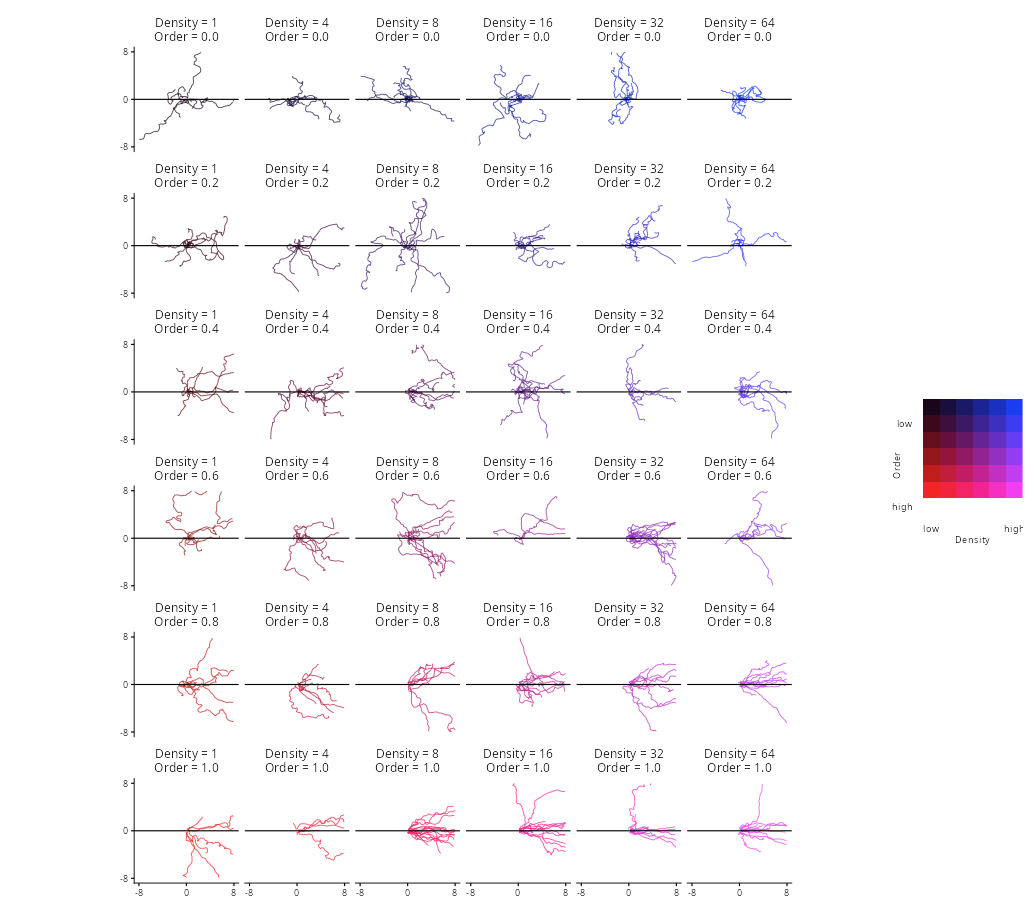

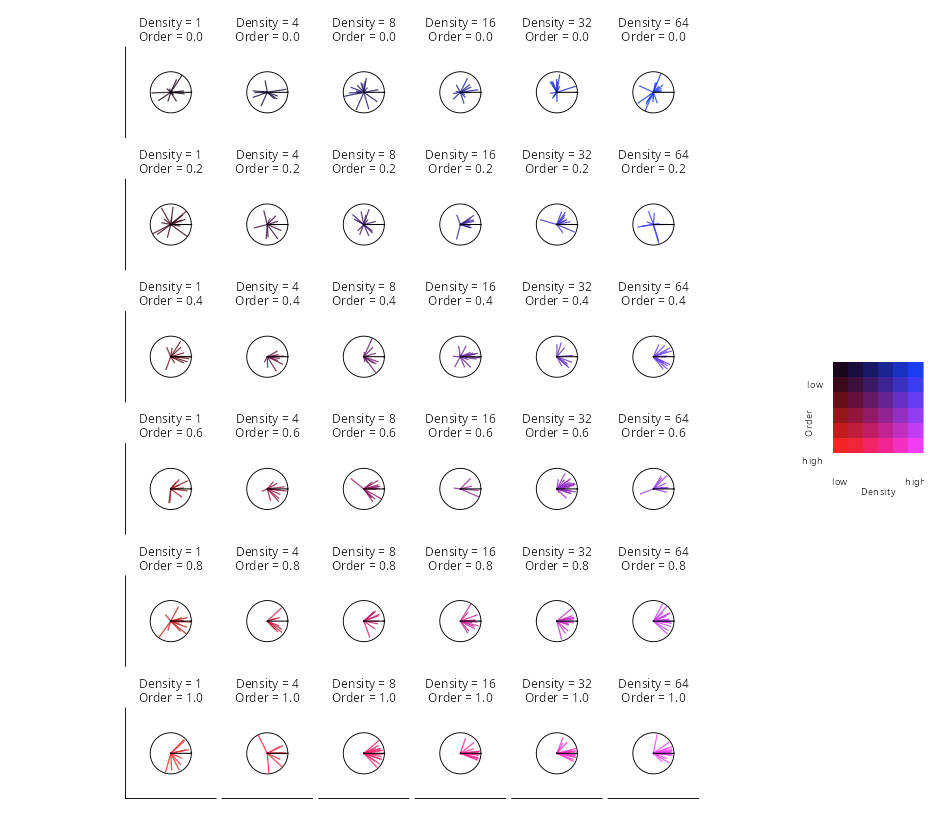

In [6]:
# Data grids: one panel per (order, density) condition, colored by the
# shared deep-purple 2D map (black -> red along order, black -> blue along
# density, channelwise max) with the square 2D key on the right. Each panel
# title names its condition; every trajectory panel shares one +/-8 m window
# and every vector panel one shared scale, so cells compare at a glance.
cell_color2 <- function(r, c2, n_rows, n_cols, tmin = 0.10, tmax = 0.95,
  blue = c(0.10, 0.25, 1.00), red = c(1.00, 0.15, 0.15), gamma = 1.15) {
  to <- tmin + (tmax - tmin) * (r / max(n_rows - 1, 1)) ^ gamma
  td <- tmin + (tmax - tmin) * (c2 / max(n_cols - 1, 1)) ^ gamma
  # Channelwise max, per-channel (no matrix ops: keeps scalar and
  # vectorised calls warning-free and dimension-stable).
  rr <- pmax(0, pmin(1, pmax(to * red[1], td * blue[1])))
  gg <- pmax(0, pmin(1, pmax(to * red[2], td * blue[2])))
  bb <- pmax(0, pmin(1, pmax(to * red[3], td * blue[3])))
  sprintf("#%02X%02X%02X", round(rr * 255), round(gg * 255), round(bb * 255))
}
orders_g <- sort(unique(merged_df$order))       # low at top -> high at bottom
densities_g <- sort(unique(merged_df$density))  # low at left -> high at right
n_rows_g <- length(orders_g)
n_cols_g <- length(densities_g)
stopifnot(all(table(merged_df$order, merged_df$density) > 0))
cell_title <- function(o, d)
  paste0("Density = ", format(d, nsmall = 1, trim = TRUE), "\nOrder = ", format(o, nsmall = 1))
gtitle_levels <- unlist(lapply(orders_g, function(o)
  vapply(densities_g, function(d) cell_title(o, d), character(1))))
merged_df$gcol <- cell_color2(match(merged_df$order, orders_g) - 1L,
  match(merged_df$density, densities_g) - 1L, n_rows_g, n_cols_g)
merged_df$gtitle <- factor(cell_title(merged_df$order, merged_df$density),
  levels = gtitle_levels)
key_grid <- expand.grid(rr = 0:(n_rows_g - 1), cc = 0:(n_cols_g - 1))
key_grid$ypos <- n_rows_g - 1L - key_grid$rr
key_grid$col <- cell_color2(key_grid$rr, key_grid$cc, n_rows_g, n_cols_g)
p_key <- ggplot(key_grid, aes(x = cc + 0.5, y = ypos + 0.5, fill = col)) +
  geom_tile() +
  annotate("rect", xmin = 0, xmax = n_cols_g, ymin = 0, ymax = n_rows_g,
    fill = NA, colour = "black", linewidth = 0.28) +
  scale_fill_identity(guide = "none") +
  scale_x_continuous(limits = c(-2, n_cols_g), expand = c(0, 0)) +
  scale_y_continuous(limits = c(-6.5, n_rows_g + 6.5), expand = c(0, 0)) +
  annotate("text", x = 0.5, y = -0.85, label = "low", size = 2.3) +
  annotate("text", x = n_cols_g - 0.5, y = -0.85, label = "high", size = 2.3) +
  annotate("text", x = n_cols_g / 2, y = -1.5, label = "Density", size = 2.3) +
  annotate("text", x = -0.60, y = n_rows_g - 0.5, label = "low", hjust = 1,
    size = 2.3) +
  annotate("text", x = -0.60, y = 0.5, label = "high", hjust = 1, size = 2.3) +
  annotate("text", x = -1.60, y = n_rows_g / 2, label = "Order", angle = 90,
    size = 2.3) +
  coord_equal() +
  theme_void(base_size = 7) +
  theme(plot.margin = margin(1.5, 1.5, 1.5, 1.5, "pt"))
grid_thm <- function() theme_classic(base_size = 8) +
  theme(strip.text = element_text(size = 8, hjust = 0.5, lineheight = 0.95),
    strip.background = element_blank(),
    axis.line = element_line(colour = "black", linewidth = 0.28),
    panel.grid = element_blank(),
    panel.border = element_blank(),
    plot.margin = margin(1, 1, 1, 1, "pt"))
p_paths <- ggplot(merged_df, aes(X, Y, group = fname, colour = gcol)) +
  geom_path(linewidth = 0.28, alpha = 0.75) +
  annotate("segment", x = 0, xend = 8, y = 0, yend = 0,
    colour = "black", linewidth = 0.35) +
  facet_wrap(~ gtitle, ncol = n_cols_g, axes = "all") +
  scale_colour_identity(guide = "none") +
  scale_x_continuous(limits = c(-8, 8), breaks = c(-8, 0, 8),
    expand = c(0, 0)) +
  scale_y_continuous(limits = c(-8, 8), breaks = c(-8, 0, 8),
    expand = c(0, 0)) +
  coord_equal() +
  labs(x = "", y = "") +
  grid_thm()
save_figure(patchwork::wrap_plots(p_paths, p_key, widths = c(8.6, 1.35)),
  "trajectories_order_by_density_grid", 9.4, 8.4)
# Mean displacement per animal in step-length units (r = 1 = one 0.24 m
# step), inside the unit circle; one shared window across all panels.
nice_ceil <- function(v) {
  if (v <= 0) return(1.0)
  v <- v * 1.10
  e <- floor(log10(v))
  f <- v / 10 ^ e
  for (n in c(1.0, 2.0, 2.5, 5.0, 10.0)) if (f <= n) return(n * 10 ^ e)
  10.0 * 10 ^ e
}
vectors <- aggregate(cbind(dX, dY) ~ order + density + fname,
  data = merged_df, FUN = mean)
step_L_m <- 6 * 0.04
Lvec <- max(nice_ceil(max(abs(vectors$dX), abs(vectors$dY)) / step_L_m), 1.15)
vectors$vx <- vectors$dX / step_L_m
vectors$vy <- vectors$dY / step_L_m
vectors$gcol <- cell_color2(match(vectors$order, orders_g) - 1L,
  match(vectors$density, densities_g) - 1L, n_rows_g, n_cols_g)
vectors$gtitle <- factor(cell_title(vectors$order, vectors$density),
  levels = gtitle_levels)
circle <- data.frame(x = cos(seq(0, 2 * pi, length.out = 257)),
  y = sin(seq(0, 2 * pi, length.out = 257)))
zero_seg <- data.frame(x = 0, xend = 1, y = 0, yend = 0)
zero_tick <- data.frame(x = 0.96, xend = 1.02, y = 0, yend = 0)
p_vectors <- ggplot(vectors, aes(group = fname)) +
  geom_path(data = circle, aes(x, y), inherit.aes = FALSE, colour = "black",
    linewidth = 0.28) +
  geom_segment(aes(x = 0, y = 0, xend = vx, yend = vy, colour = gcol),
    linewidth = 0.39, alpha = 0.8) +
  geom_point(data = data.frame(x = 0, y = 0), aes(x, y), inherit.aes = FALSE,
    size = 0.12, colour = "black") +
  geom_segment(data = zero_seg, aes(x = x, y = y, xend = xend, yend = yend), inherit.aes = FALSE,
    colour = "black", linewidth = 0.32) +
  geom_segment(data = zero_tick, aes(x = x, y = y, xend = xend, yend = yend), inherit.aes = FALSE,
    colour = "black", linewidth = 0.35, lineend = "round") +
  facet_wrap(~ gtitle, ncol = n_cols_g) +
  scale_colour_identity(guide = "none") +
  scale_x_continuous(limits = c(-Lvec, Lvec), breaks = NULL) +
  scale_y_continuous(limits = c(-Lvec, Lvec), breaks = NULL) +
  coord_equal() +
  labs(x = "", y = "") +
  grid_thm() +
  theme(axis.line = element_blank())
save_figure(patchwork::wrap_plots(p_vectors, p_key, widths = c(8.6, 1.35)),
  "mean_vectors_order_by_density_grid", 8.5, 7.5)


The synthetic 6 x 6 stimulus grid previews the whole experiment: one panel
per condition, where the walk density and the walk coherence follow the
panel position, so reading from the top-left panel to the bottom-right moves
from sparse-disordered to dense-ordered stimuli. Each panel's colour comes
from the shared 2D key introduced above the data grids.


Warning message:
“Removed 109 rows containing missing values or values outside the scale range
(`geom_line()`).”


Warning message:
“Removed 111 rows containing missing values or values outside the scale range
(`geom_line()`).”


Warning message:
“Removed 125 rows containing missing values or values outside the scale range
(`geom_line()`).”


Warning message:
“Removed 294 rows containing missing values or values outside the scale range
(`geom_line()`).”


Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_line()`).”


Warning message:
“Removed 41 rows containing missing values or values outside the scale range
(`geom_line()`).”


... (59 outputs left out)

Warning message:
“Removed 280 rows containing missing values or values outside the scale range
(`geom_line()`).”


Warning message:
“Removed 560 rows containing missing values or values outside the scale range
(`geom_line()`).”


Warning message:
“Removed 1120 rows containing missing values or values outside the scale range
(`geom_line()`).”


Warning message:
“Removed 2240 rows containing missing values or values outside the scale range
(`geom_line()`).”


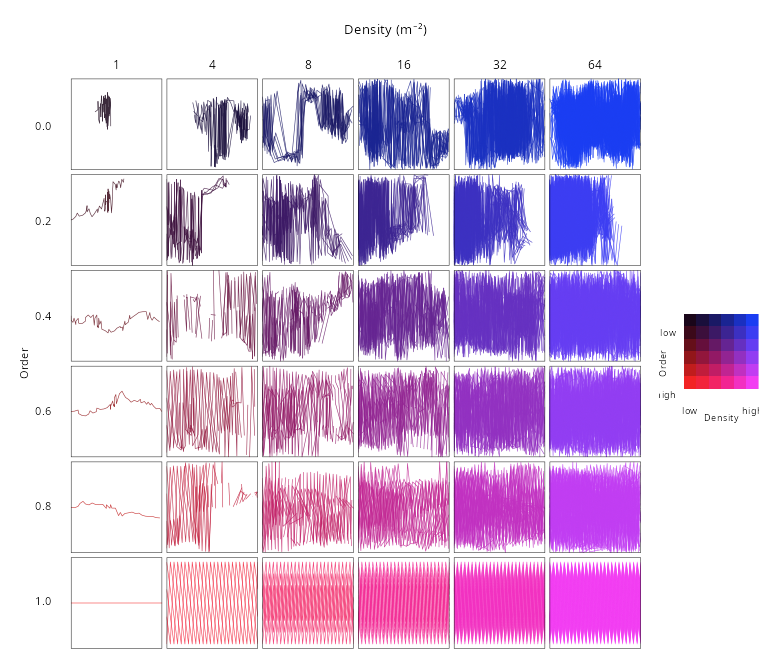

In [7]:
# Python twin: synthetic 6 x 6 order-density stimulus grid (7 x 6 figure).
# Rows = order (0.0 top -> 1.0 bottom), columns = density (1 left -> 64
# right); each panel shows density walks of 60 steps (length 0.04),
# von Mises about 0 degrees with kappa = inverse_A1(order) (order 1 is
# straight). Panel colors come from the shared deep-purple 2D map
# (black -> red along order + black -> blue along density, channelwise
# max), with the 2D color key on the right.
set.seed(SEED)
# These level vectors are consumed by the screening cells below (c15+);
# the schematic keeps using them as well.
density_levels <- c(1, 4, 8, 16, 32, 64)
order_levels <- seq(0, 1, by = 0.2)
orders_s <- order_levels
densities_s <- density_levels
n_rows_s <- length(orders_s)
n_cols_s <- length(densities_s)
n_steps_s <- 60L
step_L_s <- 0.04
cell_color_s <- function(r, c2) {
  to <- 0.10 + 0.85 * (r / (n_rows_s - 1)) ^ 1.15
  td <- 0.10 + 0.85 * (c2 / (n_cols_s - 1)) ^ 1.15
  rgb <- pmax(0, pmin(1, pmax(to * c(1.00, 0.15, 0.15),
    td * c(0.10, 0.25, 1.00))))
  sprintf("#%02X%02X%02X", round(rgb[1] * 255), round(rgb[2] * 255),
    round(rgb[3] * 255))
}
walks <- vector("list", n_rows_s * n_cols_s)
wi <- 0L
for (r in 0:(n_rows_s - 1)) {
  for (c2 in 0:(n_cols_s - 1)) {
    o <- orders_s[r + 1L]
    n_traj <- densities_s[c2 + 1L]
    wi <- wi + 1L
    set.seed(123 + 1000L * r + 10L * c2)
    if (o == 0) {
      x0 <- runif(n_traj, 0.10, 0.90)
      y0 <- runif(n_traj, 0.10, 0.90)
    } else {
      x0 <- rep(0, n_traj)
      y0 <- if (n_traj == 1L) 0.5 else seq(0.05, 0.95, length.out = n_traj)
    }
    k <- inverse_A1(o)
    pts <- matrix(0, nrow = 0, ncol = 2)
    for (i in seq_len(n_traj)) {
      if (o == 1) {
        angles <- rep(0, n_steps_s)
      } else {
        angles <- mod_circular(as.numeric(circular::rvonmises(n_steps_s,
          mu = vmu(0.0), kappa = k, control.circular = vm_ctrl)))
      }
      pts <- rbind(pts, cbind(
        c(x0[i], x0[i] + cumsum(step_L_s * cos(angles))),
        c(y0[i], y0[i] + cumsum(step_L_s * sin(angles)))))
    }
    walks[[wi]] <- data.frame(o = r + 1L, d = c2 + 1L,
      i = rep(seq_len(n_traj), each = n_steps_s + 1L),
      x = pts[, 1], y = pts[, 2])
  }
}
schematic <- do.call(rbind, walks)
schematic$o_lab <- factor(orders_s[schematic$o],
  levels = orders_s, labels = format(orders_s, nsmall = 1))
schematic$d_lab <- factor(densities_s[schematic$d],
  levels = densities_s, labels = format(densities_s))
schematic$cell <- mapply(cell_color_s, schematic$o - 1L, schematic$d - 1L)
schematic$lw <- ifelse(densities_s[schematic$d] >= 16, 0.11, 0.19)

border_thm <- element_rect(colour = "black", linewidth = 0.28, fill = NA)
p_panels <- list()
for (r in 0:(n_rows_s - 1)) {
  for (c2 in 0:(n_cols_s - 1)) {
    sub <- schematic[schematic$o == r + 1L & schematic$d == c2 + 1L, ,
      drop = FALSE]
    p <- ggplot(sub[densities_s[sub$d] < 16, , drop = FALSE],
      aes(x, y, group = i, colour = cell)) +
      geom_path(data = sub[densities_s[sub$d] >= 16, , drop = FALSE],
        aes(x, y, group = i, colour = cell),
        linewidth = 0.11, alpha = 0.85) +
      geom_path(linewidth = 0.19, alpha = 0.85) +
      scale_colour_identity(guide = "none") +
      scale_x_continuous(limits = c(0, 1), expand = c(0, 0)) +
      scale_y_continuous(limits = c(0, 1), expand = c(0, 0)) +
      coord_equal() +
      theme_void() +
      theme(panel.border = border_thm,
        plot.margin = margin(1.5, 1.5, 1.5, 1.5, "pt"),
        plot.title = element_text(size = 8, hjust = 0.5))
    if (r == 0L) {
      p <- p + labs(title = format(densities_s[c2 + 1L]))
    }
    p_panels[[length(p_panels) + 1L]] <- p
  }
}
grid_block <- patchwork::wrap_plots(p_panels, ncol = n_cols_s)
gutter_df <- data.frame(lbl = format(orders_s, nsmall = 1),
  y = n_rows_s:1L)
p_gutter <- ggplot(gutter_df) +
  geom_text(aes(x = 0.98, y = y, label = lbl), hjust = 1, size = 2.6) +
  annotate("text", x = 0.30, y = (n_rows_s + 1) / 2,
    label = "Order", angle = 90, size = 2.6) +
  scale_x_continuous(limits = c(0, 1), expand = c(0, 0)) +
  scale_y_continuous(limits = c(0.5, n_rows_s + 0.5), expand = c(0, 0)) +
  theme_void() +
  labs(title = "") +
  theme(plot.margin = margin(1.5, 2, 1.5, 2, "pt"))
key_grid <- expand.grid(rr = 0:(n_rows_s - 1), cc = 0:(n_cols_s - 1))
key_grid$ypos <- n_rows_s - 1L - key_grid$rr
key_grid$col <- mapply(cell_color_s, key_grid$rr, key_grid$cc)
p_key <- ggplot(key_grid, aes(x = cc + 0.5, y = ypos + 0.5, fill = col)) +
  geom_tile() +
  annotate("rect", xmin = 0, xmax = n_cols_s, ymin = 0, ymax = n_rows_s,
    fill = NA, colour = "black", linewidth = 0.28) +
  scale_fill_identity(guide = "none") +
  scale_x_continuous(limits = c(-2, n_cols_s), expand = c(0, 0)) +
  scale_y_continuous(limits = c(-6.5, n_rows_s + 6.5),
    expand = c(0, 0)) +
  annotate("text", x = 0.5, y = -0.75, label = "low", size = 2.3) +
  annotate("text", x = n_cols_s - 0.5, y = -0.75, label = "high",
    size = 2.3) +
  annotate("text", x = n_cols_s / 2, y = -1.35, label = "Density",
    size = 2.3) +
  annotate("text", x = -0.60, y = n_rows_s - 0.5, label = "low",
    hjust = 1, size = 2.3) +
  annotate("text", x = -0.60, y = 0.5, label = "high", hjust = 1,
    size = 2.3) +
  annotate("text", x = -1.75, y = n_rows_s / 2, label = "Order",
    angle = 90, size = 2.3) +
  coord_equal() +
  labs(title = "") +
  theme_void(base_size = 7) +
  theme(plot.margin = margin(1.5, 1.5, 1.5, 1.5, "pt"))
p_title <- ggplot(data.frame(), aes(x = 0, y = 0)) +
  annotate("text", x = 0.5, y = 0.5, label = "Density (m\u207b\u00b2)",
    size = 3.2) +
  scale_x_continuous(limits = c(0, 1), expand = c(0, 0)) +
  scale_y_continuous(limits = c(0, 1), expand = c(0, 0)) +
  theme_void()
p_stimulus <- patchwork::wrap_plots(
  p_title,
  patchwork::wrap_plots(p_gutter, grid_block, p_key,
    widths = c(0.4, 6, 1)),
  ncol = 1, heights = c(0.07, 1))
save_figure(p_stimulus, "order_density_pairwise_trajectories_only", 7, 6)


A compact schematic of the two stimulus dimensions. On the left, the
virtual neighbours: the dot count is the density (more neighbours, more
dots, darker red). On the right, those neighbours' motion: 12 walkers each
take 100 unit steps, and the order controls how coherent their headings are
(0 = random directions, 1 = all walking straight to the right). The top row
is the strongest stimulus. The schematic is illustrative only; it never
enters a fit.


Warning message:
“Removed 1212 rows containing missing values or values outside the scale range
(`geom_path()`).”


Warning message:
“Removed 860 rows containing missing values or values outside the scale range
(`geom_path()`).”


Warning message:
“Removed 790 rows containing missing values or values outside the scale range
(`geom_path()`).”


Warning message:
“Removed 491 rows containing missing values or values outside the scale range
(`geom_path()`).”


Warning message:
“Removed 172 rows containing missing values or values outside the scale range
(`geom_path()`).”


Warning message:
“Removed 1212 rows containing missing values or values outside the scale range
(`geom_path()`).”


... (2 outputs left out)

Warning message:
“Removed 790 rows containing missing values or values outside the scale range
(`geom_path()`).”


Warning message:
“Removed 491 rows containing missing values or values outside the scale range
(`geom_path()`).”


Warning message:
“Removed 172 rows containing missing values or values outside the scale range
(`geom_path()`).”


Warning message:
“Removed 1212 rows containing missing values or values outside the scale range
(`geom_path()`).”


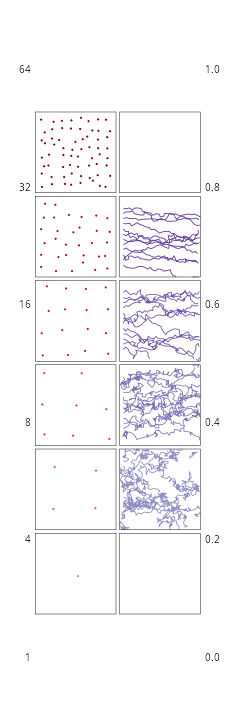

In [8]:
# Synthetic stimulus schematic (6 rows x 2 columns): density dots on the
# left (reds), coherent walkers on the right (purples).
sc_orders <- c(1.0, 0.8, 0.6, 0.4, 0.2, 0.0)
sc_denss <- c(64, 32, 16, 8, 4, 1)
sc_reds <- c("64" = "#7E0610", "32" = "#AC1117", "16" = "#CA181D",
  "8" = "#E83429", "4" = "#F6583E", "1" = "#FB7A5A")
sc_purps <- c("1.0" = "#470F84", "0.8" = "#582F93", "0.6" = "#6950A3",
  "0.4" = "#7B74B5", "0.2" = "#928FC3", "0.0" = "#AAA8D0")
sc_A1 <- function(k)
  besselI(k, 1, expon.scaled = TRUE) / besselI(k, 0, expon.scaled = TRUE)
sc_kappa <- function(o) {
  if (o <= 0) return(0)
  if (o >= 1) return(Inf)
  uniroot(function(k) sc_A1(k) - o, c(1e-8, 500))$root
}
sc_n_traj <- 12L
sc_n_steps <- 100L
sc_step <- 0.04
sc_box <- theme_void() +
  theme(panel.border = element_rect(colour = "black", fill = NA,
    linewidth = 0.28),
    plot.margin = margin(1, 1, 1, 1, "pt"))
set.seed(123)
p_dots <- vector("list", 6)
p_walks <- vector("list", 6)
for (r in seq_len(6)) {
  d <- sc_denss[r]
  if (d == 1L) {
    xs <- 0.5; ys <- 0.5
  } else if (d == 4L) {
    g <- expand.grid(c(0.25, 0.75), c(0.25, 0.75))
    xs <- g$Var1; ys <- g$Var2
  } else {
    ns <- ceiling(sqrt(d))
    axis_seq <- seq(0.1, 0.9, length.out = ns)
    g <- expand.grid(axis_seq, axis_seq)
    xs <- g$Var1[seq_len(d)]
    ys <- g$Var2[seq_len(d)]
  }
  xs <- pmin(0.925, pmax(0.075, xs + rnorm(length(xs), 0, 0.025)))
  ys <- pmin(0.925, pmax(0.075, ys + rnorm(length(ys), 0, 0.025)))
  p_dots[[r]] <- ggplot(data.frame(x = xs, y = ys), aes(x, y)) +
    geom_point(size = 0.06, colour = sc_reds[as.character(d)]) +
    scale_x_continuous(limits = c(0, 1), expand = c(0, 0)) +
    scale_y_continuous(limits = c(0, 1), expand = c(0, 0)) +
    coord_equal() + sc_box
  o <- sc_orders[r]
  k <- sc_kappa(o)
  if (o == 0) {
    x0 <- runif(sc_n_traj, 0.1, 0.9)
    y0 <- runif(sc_n_traj, 0.1, 0.9)
  } else {
    x0 <- rep(0.05, sc_n_traj)
    y0 <- seq(0.15, 0.85, length.out = sc_n_traj)
  }
  pts <- data.frame()
  for (i in seq_len(sc_n_traj)) {
    angles <- if (o == 1) rep(0, sc_n_steps)
      else as.numeric(circular::rvonmises(sc_n_steps, mu = vmu(0.0),
        kappa = k, control.circular = vm_ctrl))
    pts <- rbind(pts, data.frame(
      i = i,
      x = c(x0[i], x0[i] + cumsum(sc_step * cos(angles))),
      y = c(y0[i], y0[i] + cumsum(sc_step * sin(angles)))))
  }
  p_walks[[r]] <- ggplot(pts, aes(x, y, group = i)) +
    geom_path(linewidth = 0.25, colour = sc_purps[sprintf("%.1f", o)]) +
    scale_x_continuous(limits = c(0, 1), expand = c(0, 0)) +
    scale_y_continuous(limits = c(0, 1), expand = c(0, 0)) +
    coord_equal() + sc_box
}
gutters_l <- data.frame(y = rev(seq_len(6)), lbl = as.character(sc_denss))
gutters_r <- data.frame(y = rev(seq_len(6)),
  lbl = format(sc_orders, nsmall = 1))
p_gut_l <- ggplot(gutters_l) +
  geom_text(aes(x = 0.9, y = y, label = lbl), hjust = 1, size = 2.4) +
  scale_y_continuous(limits = c(0.5, 6.5), expand = c(0, 0)) +
  scale_x_continuous(limits = c(0, 1), expand = c(0, 0)) +
  theme_void()
p_gut_r <- ggplot(gutters_r) +
  geom_text(aes(x = 0.1, y = y, label = lbl), hjust = 0, size = 2.4) +
  scale_y_continuous(limits = c(0.5, 6.5), expand = c(0, 0)) +
  scale_x_continuous(limits = c(0, 1), expand = c(0, 0)) +
  theme_void()
p_schematic <- patchwork::wrap_plots(
  patchwork::wrap_plots(p_gut_l,
    patchwork::wrap_plots(p_dots, ncol = 1),
    patchwork::wrap_plots(p_walks, ncol = 1), p_gut_r,
    widths = c(0.30, 1, 1, 0.38)),
  ncol = 1)
save_figure(p_schematic, "order_density_trajectories", 2.2, 6.6)


## 2. Build the individual screening table

Average each animal's displacement vectors, then take their angle:
$y=\operatorname{atan2}(\overline{dY},\overline{dX})$. This is one
observation per animal. Order is scaled as `2 * order - 1` and density
as `2 * log2(density) / log2(64) - 1`. The initial interaction fit is
uncentered; the five-model sweep that follows uses default predictor
centering.


In [9]:
screen_df <- vectors[order(vectors$order, vectors$density, vectors$fname), ]
screen_df$y <- mod_circular(atan2(screen_df$dY, screen_df$dX))
screen_df$t_order <- 2 * screen_df$order - 1
screen_df$t_density <- 2 * log2(screen_df$density) / log2(64) - 1
stopifnot(nrow(screen_df) == 440L,
          all(abs(screen_df$t_order) <= 1), all(abs(screen_df$t_density) <= 1))
head(screen_df)


,order,density,fname,dX,dY,vx,vy,gcol,gtitle,y,t_order,t_density
,<dbl>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<fct>,<dbl>,<dbl>,<dbl>
25,0,1,20220831_1031,-0.22705194,-0.006859515,-0.94604974,-0.02858131,#1A061A,Density = 1 Order = 0.0,-3.1113906,-1,-1
36,0,1,20220831_1631,-0.01440162,0.043187751,-0.06000676,0.17994896,#1A061A,Density = 1 Order = 0.0,1.8926658,-1,-1
49,0,1,20220902_1816,0.03309344,-0.026387840,0.13788935,-0.10994933,#1A061A,Density = 1 Order = 0.0,-0.6731374,-1,-1
92,0,1,20220907_1101,0.15344417,0.016937418,0.63935072,0.07057258,#1A061A,Density = 1 Order = 0.0,0.1099366,-1,-1
139,0,1,20220910_1300,-0.14585667,-0.098389933,-0.60773613,-0.40995805,#1A061A,Density = 1 Order = 0.0,-2.5481413,-1,-1
143,0,1,20220910_1524,0.06737033,0.151460286,0.28070973,0.63108452,#1A061A,Density = 1 Order = 0.0,1.1522707,-1,-1


In [10]:
diagnose_fit <- function(fit, circular_parameters = character()) {
  # NUTS divergences. Not every brms/cmdstanr combination keeps the
  # per-iteration divergence flag in the fit object, so probe for it and
  # report what the fit object actually carries (the R-hat and ESS values
  # below are the primary convergence checks either way).
  divergences <- tryCatch({
    div_flags <- lapply(fit$fit@sim$samples, function(ch) ch[["divergent"]])
    if (any(vapply(div_flags, is.null, logical(1)))) NA_real_
    else sum(unlist(div_flags))
  }, error = function(e) NA_real_)
  if (is.na(divergences)) {
      cat("Divergences: not retained in this fit object (see R-hat/ESS below).\n")
  } else {
      cat("Divergences:", divergences, "\n")
  }
  available <- posterior::variables(posterior::as_draws_array(fit))
  parameters <- available[grepl("^(b_|sd_|r_|kmu_)", available)]
  draws_array <- posterior::subset_draws(posterior::as_draws_array(fit),
                                         variable = parameters)
  out <- do.call(rbind, lapply(parameters, function(p) {
    # Preserve iteration x chain shape: flattening loses between-chain
    # information and would make the R-hat/ESS checks misleading.
    x <- as.matrix(draws_array[, , p])
    angular <- p %in% circular_parameters
    z <- if (angular) mod_circular(x - circ_mean(x)) else x
    stopifnot(all(is.finite(x)))
    data.frame(parameter = p,
      mean = if (angular) circ_mean(x) else mean(x),
      sd = if (angular) circ_sd(x) else sd(as.numeric(x)),
      rhat = if (angular) Rhat_unwrap(x, method = "sine") else posterior::rhat(x),
      ess_bulk = posterior::ess_bulk(z),
      row.names = NULL, check.names = FALSE)
  }))
  out$rhat <- round(out$rhat, 4)
  out$ess_bulk <- round(out$ess_bulk, 1)
  out
}

screen_priors <- function(rhs, centered = TRUE, uniform = FALSE) {
  cls <- if (centered) "Intercept" else "b"
  co <- if (centered) "" else "Intercept"
  p <- set_prior(if (uniform) "unwrap_von_mises(0, 2.220446049250313e-16)" else
    "unwrap_von_mises(0, 1e-6)", class = cls, coef = co) +
    set_prior("normal(log(exp(2) - 1), 1)", class = cls, coef = co, dpar = "kappa")
  if (rhs != "1") {
    terms <- c(if (grepl("t_density", rhs, fixed = TRUE)) "t_density",
               if (grepl("t_order", rhs, fixed = TRUE)) "t_order",
               if (grepl("*", rhs, fixed = TRUE)) "t_density:t_order")
    for (term in terms) {
      p <- p + set_prior("normal(0, pi()/2)", class = "b", coef = term) +
        set_prior("normal(0, 1)", class = "b", coef = term, dpar = "kappa")
    }
  }
  p
}
screen_formula <- function(rhs, centered = TRUE) {
  prefix <- if (centered) "" else "0 + Intercept + "
  bf(as.formula(paste("y ~", prefix, rhs)),
     as.formula(paste("kappa ~", prefix, rhs)), family = unwrap_von_mises)
}
SCREEN_ITER <- if (quick_run) 1500L else 2000L
SCREEN_WARMUP <- if (quick_run) 750L else 1000L
screen_fit <- unwrap_load_fit_cache("locust_d_screen_td_to", SEED, SCREEN_ITER, SCREEN_WARMUP)
if (is.null(screen_fit)) {
  screen_fit <- brm(screen_formula("t_density * t_order", centered = FALSE),
    data = screen_df,
    prior = screen_priors("t_density * t_order", centered = FALSE),
    stanvars = stan_unwrap_fun + modulo_circular_fun, backend = "cmdstanr",
    chains = CHAINS, iter = SCREEN_ITER, warmup = SCREEN_WARMUP, cores = CHAINS,
    seed = SEED, control = list(adapt_delta = 0.95))
  unwrap_save_fit_cache("locust_d_screen_td_to", screen_fit, SEED, SCREEN_ITER, SCREEN_WARMUP)
}
diagnose_fit(screen_fit, "b_Intercept")

Start sampling



Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 2 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 3 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 4 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 2 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 1 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 3 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 2 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 4 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 3 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 2 Iteration:  300 / 2000 [ 15%]  (Warmup) 
Chain 1 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 3 Iteration:  300 / 2000 [ 15%]  (Warmup) 
Chain 2 Iteration:  400 / 2000 [ 20%]  (Warmup) 
Chain 3 Iteration:  400 / 2000 [ 20%]  (Warmup) 
Chain 4 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 1 Iteration:  300 / 2000 [ 15%]  (Warmup) 
Chain 2 Iteration:  500 / 2000 [ 25%]  (Warmup) 
Chain 3 Iteration:  500 / 2000 [ 25%]  (Warmup) 
Chain 2 Iteration:  600 / 200

Loading required namespace: rstan



Divergences: not retained in this fit object (see R-hat/ESS below).


parameter,mean,sd,rhat,ess_bulk
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
b_Intercept,0.04658987,0.07942432,1.0002,2304.1
b_t_density,0.06899933,0.11349833,1.0004,2056.6
b_t_order,-0.12236274,0.10872634,0.9999,2169.6
b_t_density:t_order,0.14691281,0.15765761,1.0000,1968.1
b_kappa_Intercept,1.37013458,0.16883326,1.0000,3764.9
b_kappa_t_density,0.80450795,0.25309932,1.0019,3884.8
b_kappa_t_order,2.51758641,0.28997429,1.0010,3429.7
b_kappa_t_density:t_order,1.02501651,0.39307849,1.0000,3691.8


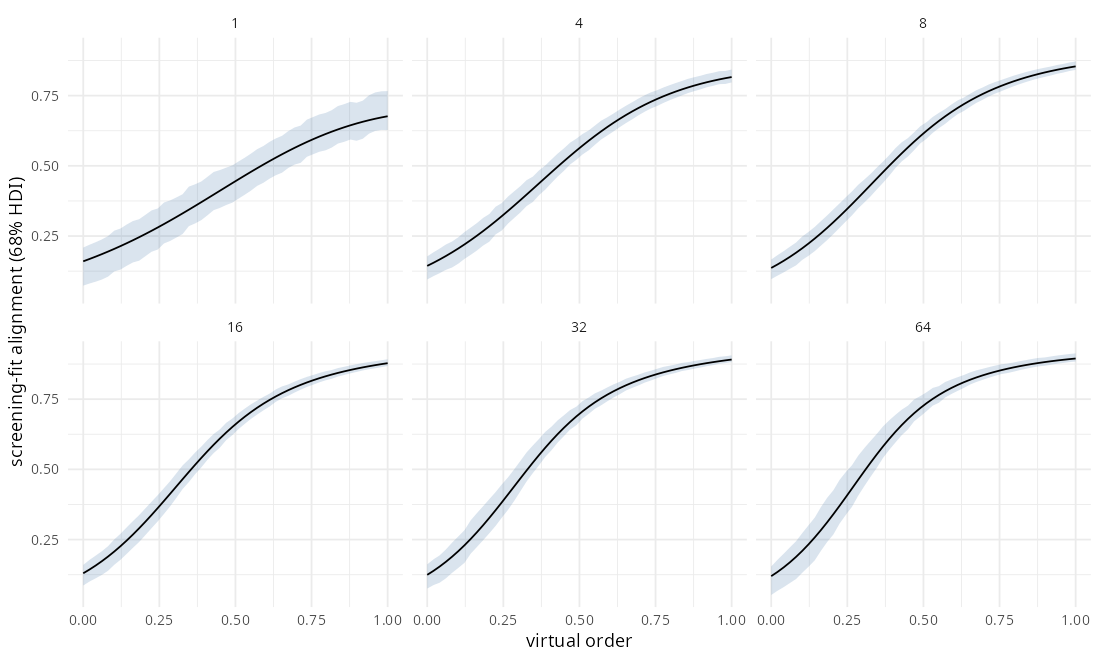

In [11]:
# Initial uncentered screening-fit alignment, 68% HDI as in Python.
screen_grid <- expand.grid(order = seq(0, 1, length.out = 50), density = density_levels)
screen_grid$t_order <- 2 * screen_grid$order - 1
screen_grid$t_density <- 2 * log2(screen_grid$density) / log2(64) - 1
screen_mu <- mod_circular(posterior_linpred(screen_fit, newdata = screen_grid,
                                            dpar = "mu", transform = FALSE))
screen_k <- posterior_linpred(screen_fit, newdata = screen_grid,
                              dpar = "kappa", transform = TRUE)
screen_alignment <- A1_safe(screen_k) * cos(screen_mu)
screen_alignment_df <- do.call(rbind, lapply(seq_len(nrow(screen_grid)), function(j) {
  data.frame(screen_grid[j, c("order", "density")],
    as.list(interval_row(screen_alignment[, j], prob = 0.68)))
}))
p_screen <- ggplot(screen_alignment_df, aes(order, mean)) +
  geom_ribbon(aes(ymin = low, ymax = high), alpha = 0.2, fill = "#4477AA") +
  geom_line() + facet_wrap(~ density) +
  labs(x = "virtual order", y = "screening-fit alignment (68% HDI)")
save_figure(p_screen, "order_density_alignment_screening", 10, 6)


## 3. Individual-level PSIS-LOO model comparison

Fit intercept-only, density, order, additive, and interaction formulas
for **both** mean direction and concentration. Use an
effectively uniform circular mean-intercept prior, Normal `(0, pi/2)` direction
slopes, pre-softplus `Normal(inverse_softplus(2), 1)` concentration
intercept and Normal `(0, 1)` concentration slopes. Preserve default
design-column centering in this sweep. All models use the same animals
in the same order. Pointwise likelihoods and PSIS-LOO are at the animal
level; this is distinct from final-fit step-level LOO.

Evaluate the log densities explicitly from the fitted `mu` and `kappa`
predictors. Pass chain-aware relative efficiencies to `loo`. The comparison reports
ELPD, model-minus-best delta ELPD, its paired SE, and maximum Pareto k.


In [12]:
explicit_loo <- function(fit, newdata, response = "y") {
  draw_index <- posterior::as_draws_df(fit)
  log_lik <- matrix(0, nrow = nrow(draw_index), ncol = nrow(newdata))
  # Keep only the full log-likelihood matrix, evaluating response parameters
  # in observation blocks to limit memory in the 18,641-step final model.
  for (start in seq.int(1L, nrow(newdata), by = 256L)) {
    ii <- seq.int(start, min(start + 255L, nrow(newdata)))
    block <- newdata[ii, , drop = FALSE]
    mu_ll <- mod_circular(posterior_linpred(fit, newdata = block,
                                            dpar = "mu", transform = FALSE))
    k_ll <- posterior_linpred(fit, newdata = block,
                              dpar = "kappa", transform = TRUE)
    log_lik[, ii] <- vm_logpdf(matrix(block[[response]], nrow = nrow(mu_ll),
      ncol = nrow(block), byrow = TRUE), mu_ll, k_ll)
  }
  # Column scaling leaves relative efficiencies unchanged and avoids
  # underflow when converting log likelihoods to likelihoods.
  likelihood <- exp(sweep(log_lik, 2, apply(log_lik, 2, max), "-"))
  r_eff <- loo::relative_eff(likelihood, chain_id = draw_index[[".chain"]])
  loo::loo(log_lik, r_eff = r_eff)
}
candidate_rhs <- c("Intercept-only" = "1", "Density" = "t_density",
  "Order" = "t_order", "Density + Order" = "t_density + t_order",
  "Density x Order" = "t_density * t_order")
# EQUIVALENCE NOTE: the sweep's CircularUniform prior is the von Mises
# (0, kappa) flat-circle convention with kappa = double-precision machine
# epsilon (2.220446049250313e-16), the exact value of the Python twin's
# CircularUniformPrior() - a unbounded-direction parameterization, not a
# bounded uniform prior on brms's centered intercept.
# Review the intercept convention in the generated Stan.
sweep_fits <- sweep_loo <- vector("list", length(candidate_rhs))
names(sweep_fits) <- names(sweep_loo) <- names(candidate_rhs)
for (name in names(candidate_rhs)) {
  cat("Fitting screening model:", name, "\n")
  rhs <- candidate_rhs[[name]]
  sweep_fits[[name]] <- unwrap_load_fit_cache(paste0("locust_d_screen_v2_", name), SEED, SCREEN_ITER, SCREEN_WARMUP)
  if (is.null(sweep_fits[[name]])) {
    sweep_fits[[name]] <- brm(screen_formula(rhs), data = screen_df,
      prior = screen_priors(rhs, uniform = TRUE),
      stanvars = stan_unwrap_fun + modulo_circular_fun, backend = "cmdstanr",
      chains = CHAINS, iter = SCREEN_ITER, warmup = SCREEN_WARMUP, cores = CHAINS,
      seed = SEED, control = list(adapt_delta = 0.95))
    unwrap_save_fit_cache(paste0("locust_d_screen_v2_", name), sweep_fits[[name]], SEED, SCREEN_ITER, SCREEN_WARMUP)
  }
  print(diagnose_fit(sweep_fits[[name]], "b_Intercept"))
  sweep_loo[[name]] <- explicit_loo(sweep_fits[[name]], screen_df)
}
elpd <- vapply(sweep_loo, function(l) l$estimates["elpd_loo", "Estimate"], numeric(1))
best_name <- names(which.max(elpd))
best_pointwise <- sweep_loo[[best_name]]$pointwise[, "elpd_loo"]
sweep_df <- do.call(rbind, lapply(names(sweep_loo), function(name) {
  l <- sweep_loo[[name]]
  delta <- l$pointwise[, "elpd_loo"] - best_pointwise
  data.frame(model = name, elpd = elpd[[name]],
    delta_elpd = sum(delta), se_delta_elpd = sqrt(length(delta) * var(delta)),
    pareto_k_max = max(l$diagnostics$pareto_k), best_model = best_name)
}))
sweep_df <- sweep_df[order(sweep_df$delta_elpd, decreasing = TRUE), ]
sweep_df

Fitting screening model: Intercept-only 


Start sampling



Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 1 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 1 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 2 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 2 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 3 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 3 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 4 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 1 Iteration:  300 / 2000 [ 15%]  (Warmup) 
Chain 1 Iteration:  400 / 2000 [ 20%]  (Warmup) 
Chain 2 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 3 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 4 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 3 Iteration:  300 / 2000 [ 15%]  (Warmup) 
Chain 1 Iteration:  500 / 2000 [ 25%]  (Warmup) 
Chain 2 Iteration:  300 / 2000 [ 15%]  (Warmup) 
Chain 3 Iteration:  400 / 2000 [ 20%]  (Warmup) 
Chain 1 Iteration:  600 / 2000 [ 30%]  (Warmup) 
Chain 2 Iteration:  400 / 2000 [ 20%]  (Warmup) 
Chain 3 Iteration:  500 / 200

Start sampling



Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 1 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 2 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 2 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 3 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 4 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 1 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 3 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 1 Iteration:  300 / 2000 [ 15%]  (Warmup) 
Chain 3 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 4 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 2 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 1 Iteration:  400 / 2000 [ 20%]  (Warmup) 
Chain 3 Iteration:  300 / 2000 [ 15%]  (Warmup) 
Chain 1 Iteration:  500 / 2000 [ 25%]  (Warmup) 
Chain 4 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 2 Iteration:  300 / 2000 [ 15%]  (Warmup) 
Chain 3 Iteration:  400 / 2000 [ 20%]  (Warmup) 
Chain 1 Iteration:  600 / 2000 [ 30%]  (Warmup) 
Chain 3 Iteration:  500 / 200

Start sampling



... (2 outputs left out)

Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 2 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 3 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 4 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 1 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 2 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 2 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 3 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 1 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 4 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 1 Iteration:  300 / 2000 [ 15%]  (Warmup) 
Chain 2 Iteration:  300 / 2000 [ 15%]  (Warmup) 
Chain 3 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 1 Iteration:  400 / 2000 [ 20%]  (Warmup) 
Chain 2 Iteration:  400 / 2000 [ 20%]  (Warmup) 
Chain 3 Iteration:  300 / 2000 [ 15%]  (Warmup) 
Chain 1 Iteration:  500 / 2000 [ 25%]  (Warmup) 
Chain 4 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 2 Iteration:  500 / 2000 [ 25%]  (Warmup) 
Chain 1 Iteration:  600 / 200

Start sampling



Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 2 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 3 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 4 Iteration:    1 / 2000 [  0%]  (Warmup) 
Chain 1 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 3 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 2 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 1 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 3 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 4 Iteration:  100 / 2000 [  5%]  (Warmup) 
Chain 1 Iteration:  300 / 2000 [ 15%]  (Warmup) 
Chain 2 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 3 Iteration:  300 / 2000 [ 15%]  (Warmup) 
Chain 1 Iteration:  400 / 2000 [ 20%]  (Warmup) 
Chain 4 Iteration:  200 / 2000 [ 10%]  (Warmup) 
Chain 3 Iteration:  400 / 2000 [ 20%]  (Warmup) 
Chain 1 Iteration:  500 / 2000 [ 25%]  (Warmup) 
Chain 2 Iteration:  300 / 2000 [ 15%]  (Warmup) 
Chain 3 Iteration:  500 / 2000 [ 25%]  (Warmup) 
Chain 1 Iteration:  600 / 200

,model,elpd,delta_elpd,se_delta_elpd,pareto_k_max,best_model
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
5,Density x Order,-590.6952,0.000000,0.000000,0.22514850,Density x Order
4,Density + Order,-592.7311,-2.035973,2.672443,0.24868885,Density x Order
3,Order,-599.7087,-9.013583,5.771863,0.14857146,Density x Order
2,Density,-666.4040,-75.708864,11.587007,0.15670142,Density x Order
1,Intercept-only,-669.2648,-78.569686,11.639198,0.08976613,Density x Order


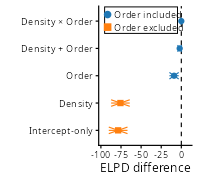

In [13]:
# Python twin: compact 1.8 x 0.33n delta-ELPD forest of the five-model
# sweep. Blue circles = order-included models, orange squares =
# order-excluded, +/-1 SE caps, best model (delta 0) on top, dashed
# zero line, framed upper-left legend, model names wrapped at width 40.
wrap_label <- function(s, width = 40)
  vapply(s, function(x) paste(strwrap(x, width = width), collapse = "\n"),
    character(1))
pretty_names <- sweep_df$model
pretty_names[pretty_names == "Density x Order"] <- "Density \u00d7 Order"
group_name <- ifelse(grepl("Order", sweep_df$model),
  "Order included", "Order excluded")
ypos <- nrow(sweep_df):1L
# Explicit limits so the annotated legend lands in stable data coordinates on both axes.
data_lo <- min(sweep_df$delta_elpd - sweep_df$se_delta_elpd)
data_hi <- max(sweep_df$delta_elpd + sweep_df$se_delta_elpd)
x_lo_sel <- data_lo - 0.08 * (data_hi - data_lo)
x_hi_sel <- data_hi + 0.08 * (data_hi - data_lo)
span_sel <- x_hi_sel - x_lo_sel
p_selection <- ggplot(sweep_df,
  aes(x = delta_elpd, y = ypos, colour = group_name, fill = group_name)) +
  geom_vline(xintercept = 0, linetype = "dashed", linewidth = 0.35) +
  geom_errorbar(aes(xmin = delta_elpd - se_delta_elpd,
    xmax = delta_elpd + se_delta_elpd), orientation = "y",
    width = 0.24, linewidth = 0.35) +
  geom_point(aes(shape = group_name), size = 1.7) +
  scale_colour_manual(values = c("Order included" = "#1F77B4",
    "Order excluded" = "#FF7F0E"), guide = "none") +
  scale_fill_manual(values = c("Order included" = "#1F77B4",
    "Order excluded" = "#FF7F0E"), guide = "none") +
  scale_shape_manual(values = c("Order included" = 16,
    "Order excluded" = 15), guide = "none") +
  scale_x_continuous(limits = c(x_lo_sel, x_hi_sel)) +
  scale_y_continuous(limits = c(0.45, nrow(sweep_df) + 0.55),
    breaks = nrow(sweep_df):1L, labels = wrap_label(pretty_names),
    expand = c(0, 0)) +
  labs(x = "ELPD difference", y = "") +
  # Framed upper-left legend (drawn by hand: this ggplot2 build
  # drops legend.position = "upperleft" without an error).
  annotate("rect", xmin = x_lo_sel + 0.02 * span_sel,
    xmax = x_lo_sel + 0.88 * span_sel, ymin = 4.55, ymax = 5.52,
    fill = "white", colour = "black", linewidth = 0.3) +
  annotate("point", x = x_lo_sel + 0.055 * span_sel, y = 5.24,
    shape = 16, colour = "#1F77B4", size = 2.1) +
  annotate("text", x = x_lo_sel + 0.135 * span_sel, y = 5.24,
    label = "Order included", hjust = 0, vjust = 0.5, size = 2.2) +
  annotate("point", x = x_lo_sel + 0.055 * span_sel, y = 4.78,
    shape = 15, colour = "#FF7F0E", size = 2.1) +
  annotate("text", x = x_lo_sel + 0.135 * span_sel, y = 4.78,
    label = "Order excluded", hjust = 0, vjust = 0.5, size = 2.2) +
  theme_classic(base_size = 8)
save_figure(p_selection, "order_density_model_selection", 1.8,
  0.33 * nrow(sweep_df))

## 4. Final step-level hierarchical model

The final model is `y ~ t_density * t_order` with
`kappa ~ t_density * t_order + (1 | animal_id)`. Mean direction has no
random effects: each animal experiences one condition, and the
per-animal direction hierarchy proved weakly identified on this design.
Use all steps.

The direction intercept has `VonMises(0, 3)`, direction main effects
`Normal(0, pi/2)` and interaction `Normal(0, pi/4)`. Pre-softplus
concentration intercept: `Normal(inverse_softplus(2), 0.5)`; main effects
`Normal(0, 0.6)` and interaction `Normal(0, 0.4)`. The individual
concentration intercept is Normal with a positive scale drawn from
`Normal(inverse_softplus(1), 0.3)`. Default internal
predictor centering is retained, including the interaction design column;
do not manually center the two predictors before taking their product.


In [14]:
data <- merged_df
data$y <- mod_circular(data$direction)
data$t_order <- 2 * data$order - 1
data$t_density <- 2 * log2(data$density) / log2(64) - 1
form_vonmises <- bf(y ~ t_density * t_order,
  kappa ~ t_density * t_order + (1 | animal_id), family = unwrap_von_mises)
prior_vonmises <- (
  prior("unwrap_von_mises(0, 3)", class = "Intercept") +
  prior("normal(0, pi()/2)", class = "b", coef = "t_density") +
  prior("normal(0, pi()/2)", class = "b", coef = "t_order") +
  prior("normal(0, pi()/4)", class = "b", coef = "t_density:t_order") +
  prior("normal(log(exp(2) - 1), 0.5)", class = "Intercept", dpar = "kappa") +
  prior("normal(0, 0.6)", class = "b", coef = "t_density", dpar = "kappa") +
  prior("normal(0, 0.6)", class = "b", coef = "t_order", dpar = "kappa") +
  prior("normal(0, 0.4)", class = "b", coef = "t_density:t_order", dpar = "kappa") +
  prior("normal(log(exp(1) - 1), 0.3)", class = "sd", dpar = "kappa")
)
# SD EQUIVALENCE NOTE (framework exception, random-effect
# parameterization): Python places Normal(mu = inverse_softplus(1), sigma
# = 0.3) on a FREE real coordinate and maps it to the positive scale with
# a softplus link (sigma = softplus(eta)). brms has no link machinery for
# a random-effect sd: its sd is a plain positive parameter, so the same
# Normal(mu, sigma) applies directly on the positive scale (truncated at
# 0). Location and scale are identical on both sides; the difference is
# confined to the 0-truncation of a Normal whose mode is at
# softplus(exp(1) - 1) = 1, far from 0 - an admitted framework-forced
# random-effect difference, not a fitted-quantity discrepancy.
# EQUIVALENCE NOTE: brms and Bambi internally center design columns while
# returning ordinary-scale intercept draws. posterior_linpred handles that
# conversion. Do not reuse the Python posthoc helper's manually centered
# interaction grid here; check fitted predictions against the PyMC graph.
prior_vonmises

prior,class,coef,group,resp,dpar,nlpar,lb,ub,tag,source
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
"unwrap_von_mises(0, 3)",Intercept,,,,,,NA,NA,,user
"normal(0, pi()/2)",b,t_density,,,,,NA,NA,,user
"normal(0, pi()/2)",b,t_order,,,,,NA,NA,,user
"normal(0, pi()/4)",b,t_density:t_order,,,,,NA,NA,,user
"normal(log(exp(2) - 1), 0.5)",Intercept,,,,kappa,,NA,NA,,user
"normal(0, 0.6)",b,t_density,,,kappa,,NA,NA,,user
"normal(0, 0.6)",b,t_order,,,kappa,,NA,NA,,user
"normal(0, 0.4)",b,t_density:t_order,,,kappa,,NA,NA,,user
"normal(log(exp(1) - 1), 0.3)",sd,,,,kappa,,NA,NA,,user


In [15]:
fit <- unwrap_load_fit_cache("locust_d_final", SEED, ITER, WARMUP)
if (is.null(fit)) {
  fit <- brm(form_vonmises, data = data, prior = prior_vonmises,
    stanvars = stan_unwrap_fun + modulo_circular_fun, backend = "cmdstanr",
    chains = CHAINS, iter = ITER, warmup = WARMUP, cores = CHAINS,
    seed = SEED, control = list(adapt_delta = ADAPT_DELTA))
  unwrap_save_fit_cache("locust_d_final", fit, SEED, ITER, WARMUP)
}


Start sampling



Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 3000 [  0%]  (Warmup) 
Chain 2 Iteration:    1 / 3000 [  0%]  (Warmup) 
Chain 3 Iteration:    1 / 3000 [  0%]  (Warmup) 
Chain 4 Iteration:    1 / 3000 [  0%]  (Warmup) 
Chain 3 Iteration:  100 / 3000 [  3%]  (Warmup) 
Chain 1 Iteration:  100 / 3000 [  3%]  (Warmup) 
Chain 3 Iteration:  200 / 3000 [  6%]  (Warmup) 
Chain 3 Iteration:  300 / 3000 [ 10%]  (Warmup) 
Chain 1 Iteration:  200 / 3000 [  6%]  (Warmup) 
Chain 3 Iteration:  400 / 3000 [ 13%]  (Warmup) 
Chain 3 Iteration:  500 / 3000 [ 16%]  (Warmup) 
Chain 1 Iteration:  300 / 3000 [ 10%]  (Warmup) 
Chain 3 Iteration:  600 / 3000 [ 20%]  (Warmup) 
Chain 1 Iteration:  400 / 3000 [ 13%]  (Warmup) 
Chain 3 Iteration:  700 / 3000 [ 23%]  (Warmup) 
Chain 4 Iteration:  100 / 3000 [  3%]  (Warmup) 
Chain 1 Iteration:  500 / 3000 [ 16%]  (Warmup) 
Chain 3 Iteration:  800 / 3000 [ 26%]  (Warmup) 
Chain 1 Iteration:  600 / 3000 [ 20%]  (Warmup) 
Chain 2 Iteration:  100 / 300

## Diagnostics and traces

Inspect the divergence probe, circular-intercept R-hat, ordinary R-hat
for the remaining coefficients and group effects, and bulk ESS. The
summary includes the individual concentration effects and their scale.


In [16]:
circular_parameters <- "b_Intercept"
summary_frame <- diagnose_fit(fit, circular_parameters)
summary_frame


Divergences: not retained in this fit object (see R-hat/ESS below).


parameter,mean,sd,rhat,ess_bulk
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
b_Intercept,-0.06659563,0.01358107,1.0000,2564.8
b_kappa_Intercept,0.44081495,0.11158881,1.0001,628.0
b_t_density,-0.14299604,0.01954309,1.0000,3341.4
b_t_order,0.07231333,0.01757580,1.0005,2923.6
b_t_density:t_order,0.15548190,0.02670601,0.9998,3391.2
b_kappa_t_density,0.41304588,0.16353725,0.9999,683.7
b_kappa_t_order,2.32697220,0.16073447,1.0066,691.0
b_kappa_t_density:t_order,0.64412781,0.21170395,1.0011,1090.2
sd_animal_id__kappa_Intercept,1.91849645,0.08659161,1.0002,1445.5


In [17]:
summary_frame[!is.finite(summary_frame$rhat) | summary_frame$rhat >= 1.01 |
              !is.finite(summary_frame$ess_bulk) | summary_frame$ess_bulk <= 400, ]


parameter,mean,sd,rhat,ess_bulk
<chr>,<dbl>,<dbl>,<dbl>,<dbl>


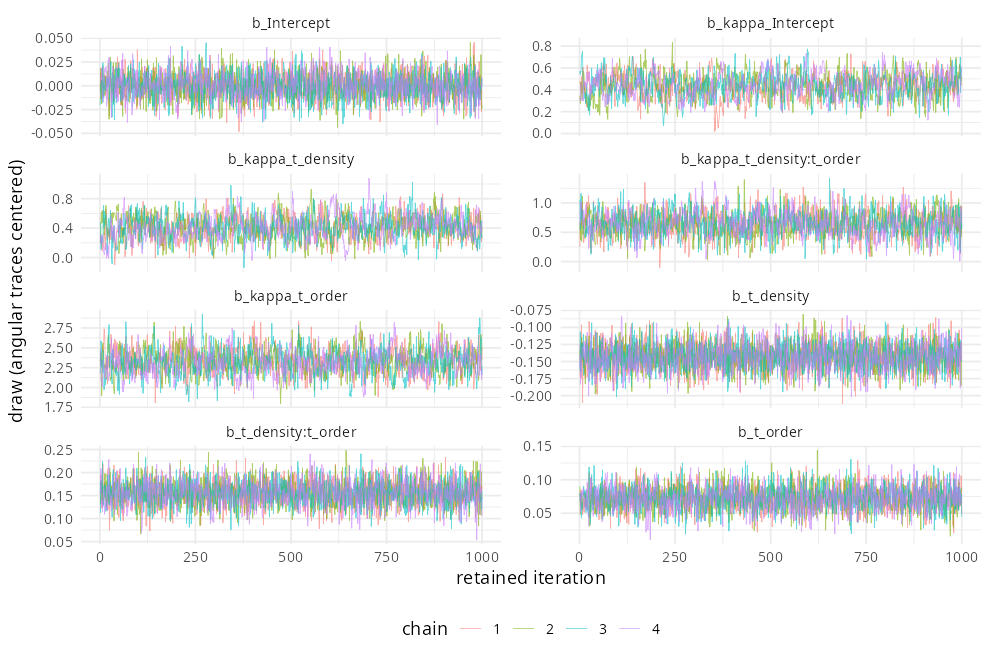

In [18]:
trace_parameters <- c("b_Intercept", "b_t_density", "b_t_order", "b_t_density:t_order",
  "b_kappa_Intercept", "b_kappa_t_density", "b_kappa_t_order", "b_kappa_t_density:t_order")

# as_draws_df is wide: explicitly assemble a long trace table.
draws_df <- posterior::as_draws_df(posterior::subset_draws(
    posterior::as_draws_array(fit), variable = trace_parameters))
trace_df <- do.call(rbind, lapply(trace_parameters, function(p) {
  value <- as.numeric(draws_df[[p]])
  if (p %in% circular_parameters) value <- mod_circular(value - circ_mean(value))
  data.frame(parameter = p, value = value,
             iteration = draws_df[[".iteration"]],
             chain = factor(draws_df[[".chain"]]))
}))
p_trace <- ggplot(trace_df, aes(iteration, value, colour = chain)) +
  geom_line(alpha = 0.6, linewidth = 0.25) +
  facet_wrap(~ parameter, scales = "free_y", ncol = 2) +
  labs(x = "retained iteration", y = "draw (angular traces centered)") +
  theme(legend.position = "bottom")
save_figure(p_trace, "trace", 9, 6)


In [19]:
# Step-level conditional LOO, as in the Python final-fit notebook.
# This is not leave-one-animal-out validation and is not compared against
# the individual-level screening ELPDs.
final_loo <- explicit_loo(fit, data)
final_loo
c(p_loo = final_loo$estimates["p_loo", "Estimate"],
  N_over_p_loo = nrow(data) / final_loo$estimates["p_loo", "Estimate"],
  fraction_pareto_k_above_0.7 = mean(final_loo$diagnostics$pareto_k > 0.7))


Warning message:
“Some Pareto k diagnostic values are too high. See help('pareto-k-diagnostic') for details.
”



Computed from 4000 posterior draws and 18641 log-likelihood terms.

         Estimate    SE
elpd_loo -26225.1 103.2
p_loo       281.9   6.6
looic     52450.2 206.3
------
MCSE of elpd_loo is NA.
MCSE and ESS estimates assume MCMC draws (r_eff in [0.3, 2.6]).

Pareto k diagnostic values:
                         Count Pct.    Min. ESS
(-Inf, 0.7]   (good)     18600 99.8%   130     
   (0.7, 1]   (bad)         18  0.1%   <NA>    
   (1, Inf)   (very bad)    23  0.1%   <NA>    
See help('pareto-k-diagnostic') for details.

p_loo                N_over_p_loo 
               2.818911e+02                6.612836e+01 
fraction_pareto_k_above_0.7 
               2.199453e-03

## 5. Predictions: alignment, density at zero, and directional PDFs

Evaluate `mu` and positive `kappa` with the fitted brms predictors.
Population curves exclude individual deviations, so they describe an
animal with a zero concentration deviation. These curves are not marginal averages over new
individuals. Predictive density at zero is a density per radian, distinct
from probability mass in an angular sector.


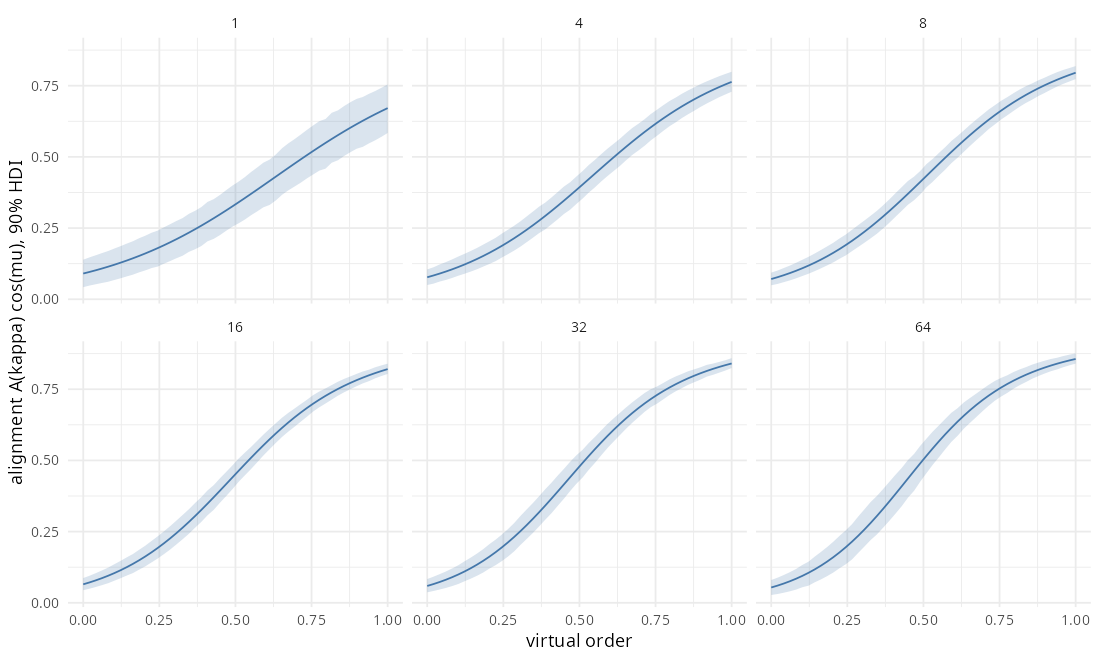

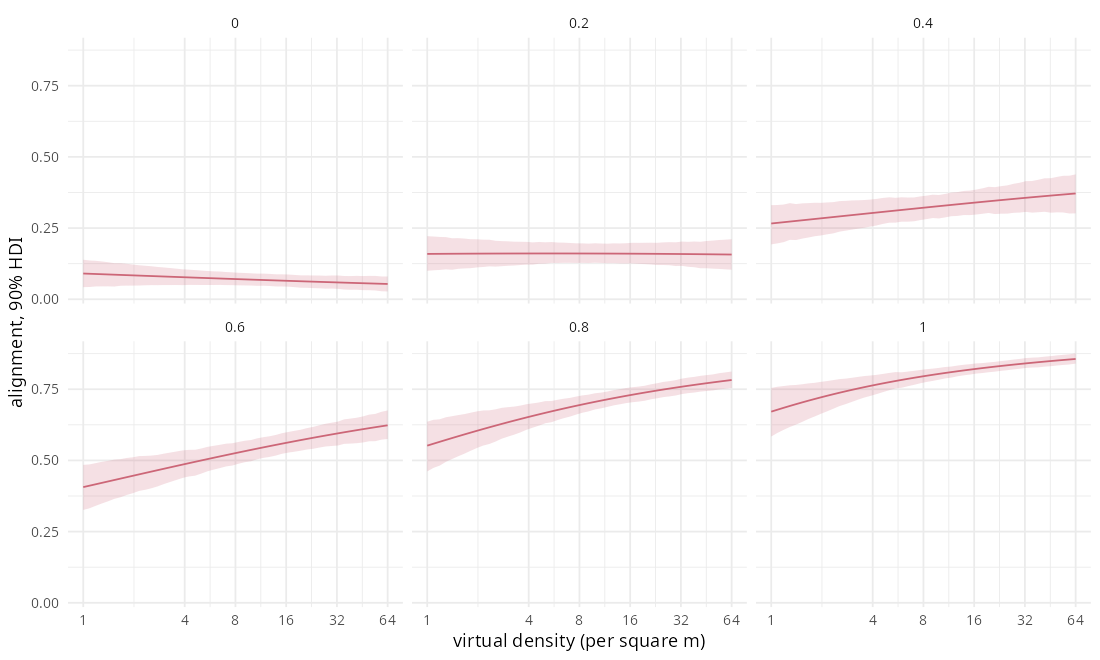

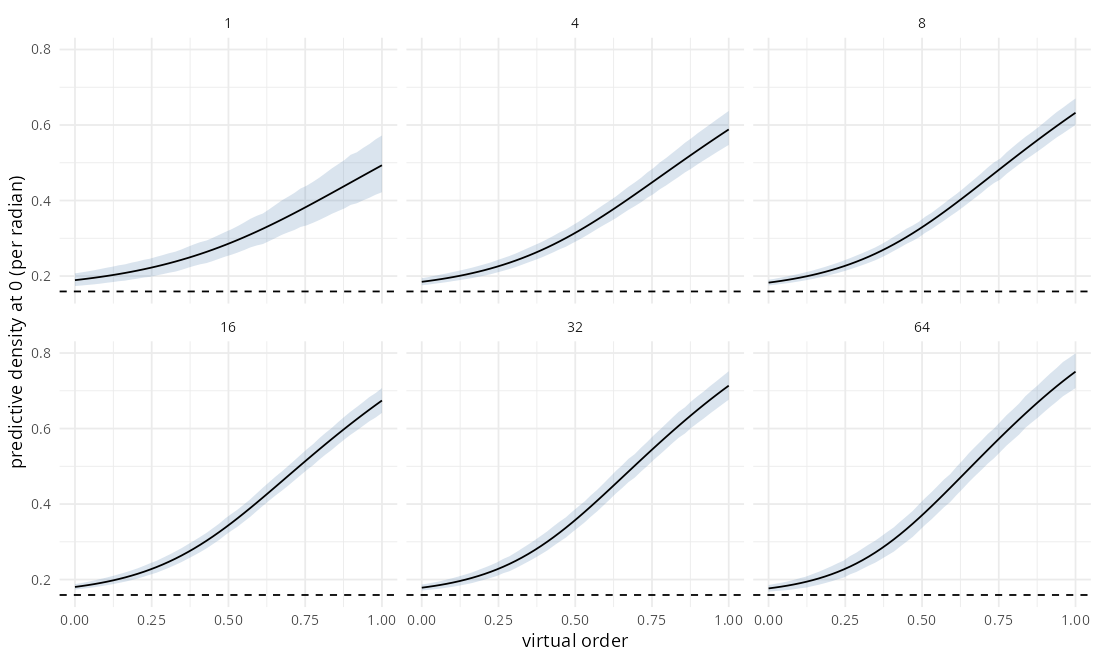

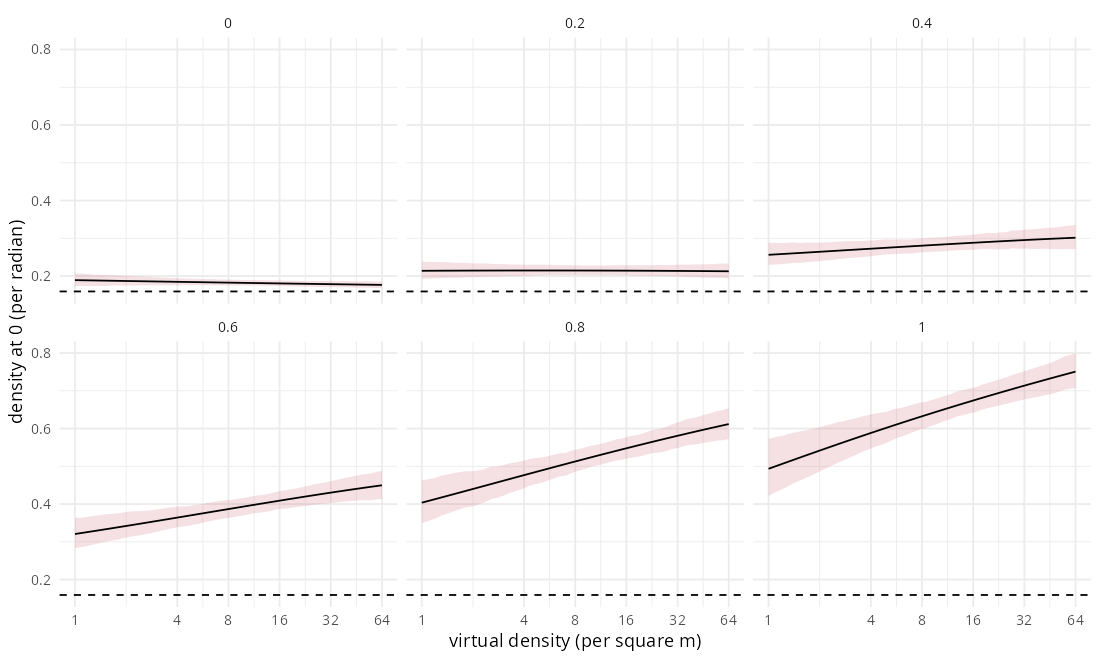

In [20]:
grid <- expand.grid(order = seq(0, 1, length.out = 50), density = density_levels)
grid$t_order <- 2 * grid$order - 1
grid$t_density <- 2 * log2(grid$density) / log2(64) - 1
grid$animal_id <- data$animal_id[1]
mu_grid <- mod_circular(posterior_linpred(fit, newdata = grid,
  dpar = "mu", transform = FALSE, re_formula = NA))
k_grid <- posterior_linpred(fit, newdata = grid,
  dpar = "kappa", transform = TRUE, re_formula = NA)
alignment <- A1_safe(k_grid) * cos(mu_grid)
alignment_summary <- do.call(rbind, lapply(seq_len(nrow(grid)), function(j) {
  data.frame(grid[j, c("order", "density")], as.list(interval_row(alignment[, j], prob = 0.9)))
}))
p_alignment <- ggplot(alignment_summary, aes(order, mean)) +
  geom_ribbon(aes(ymin = low, ymax = high), fill = "#4477AA", alpha = 0.2) +
  geom_line(colour = "#4477AA") + facet_wrap(~ density) +
  labs(x = "virtual order", y = "alignment A(kappa) cos(mu), 90% HDI")
save_figure(p_alignment, "order_density_alignment", 10, 6)

density_grid <- expand.grid(density = 2^seq(0, 6, length.out = 50), order = order_levels)
density_grid$t_order <- 2 * density_grid$order - 1
density_grid$t_density <- 2 * log2(density_grid$density) / log2(64) - 1
density_grid$animal_id <- data$animal_id[1]
mu_density <- mod_circular(posterior_linpred(fit, newdata = density_grid,
  dpar = "mu", transform = FALSE, re_formula = NA))
k_density <- posterior_linpred(fit, newdata = density_grid,
  dpar = "kappa", transform = TRUE, re_formula = NA)
density_summary <- do.call(rbind, lapply(seq_len(nrow(density_grid)), function(j) {
  data.frame(density_grid[j, c("order", "density")],
    as.list(interval_row(A1_safe(k_density[, j]) * cos(mu_density[, j]), prob = 0.9)))
}))
p_density_alignment <- ggplot(density_summary, aes(density, mean)) +
  geom_ribbon(aes(ymin = low, ymax = high), fill = "#CC6677", alpha = 0.2) +
  geom_line(colour = "#CC6677") + scale_x_continuous(trans = "log2", breaks = density_levels) +
  facet_wrap(~ order) + labs(x = "virtual density (per square m)", y = "alignment, 90% HDI")
save_figure(p_density_alignment, "density_order_alignment", 10, 6)

summarize_log_density <- function(m, k, newdata) {
  do.call(rbind, lapply(seq_len(nrow(newdata)), function(j) {
    lp <- vm_logpdf(0, m[, j], k[, j])
    # Python summarizes in log space, then exponentiates the interval.
    s <- interval_row(lp, prob = 0.9)
    data.frame(newdata[j, c("order", "density")], as.list(exp(s)))
  }))
}
pdf0 <- summarize_log_density(mu_grid, k_grid, grid)
p_pdf0 <- ggplot(pdf0, aes(order, mean)) +
  geom_ribbon(aes(ymin = low, ymax = high), alpha = 0.2, fill = "#4477AA") +
  geom_line() + geom_hline(yintercept = 1 / (2 * pi), linetype = "dashed") +
  facet_wrap(~ density) + labs(x = "virtual order", y = "predictive density at 0 (per radian)")
save_figure(p_pdf0, "order_density_elpd0", 10, 6)
pdf0_density <- summarize_log_density(mu_density, k_density, density_grid)
p_pdf0_density <- ggplot(pdf0_density, aes(density, mean)) +
  geom_ribbon(aes(ymin = low, ymax = high), alpha = 0.2, fill = "#CC6677") +
  geom_line() + geom_hline(yintercept = 1 / (2 * pi), linetype = "dashed") +
  scale_x_continuous(trans = "log2", breaks = density_levels) +
  facet_wrap(~ order) + labs(x = "virtual density (per square m)", y = "density at 0 (per radian)")
save_figure(p_pdf0_density, "density_order_elpd0", 10, 6)


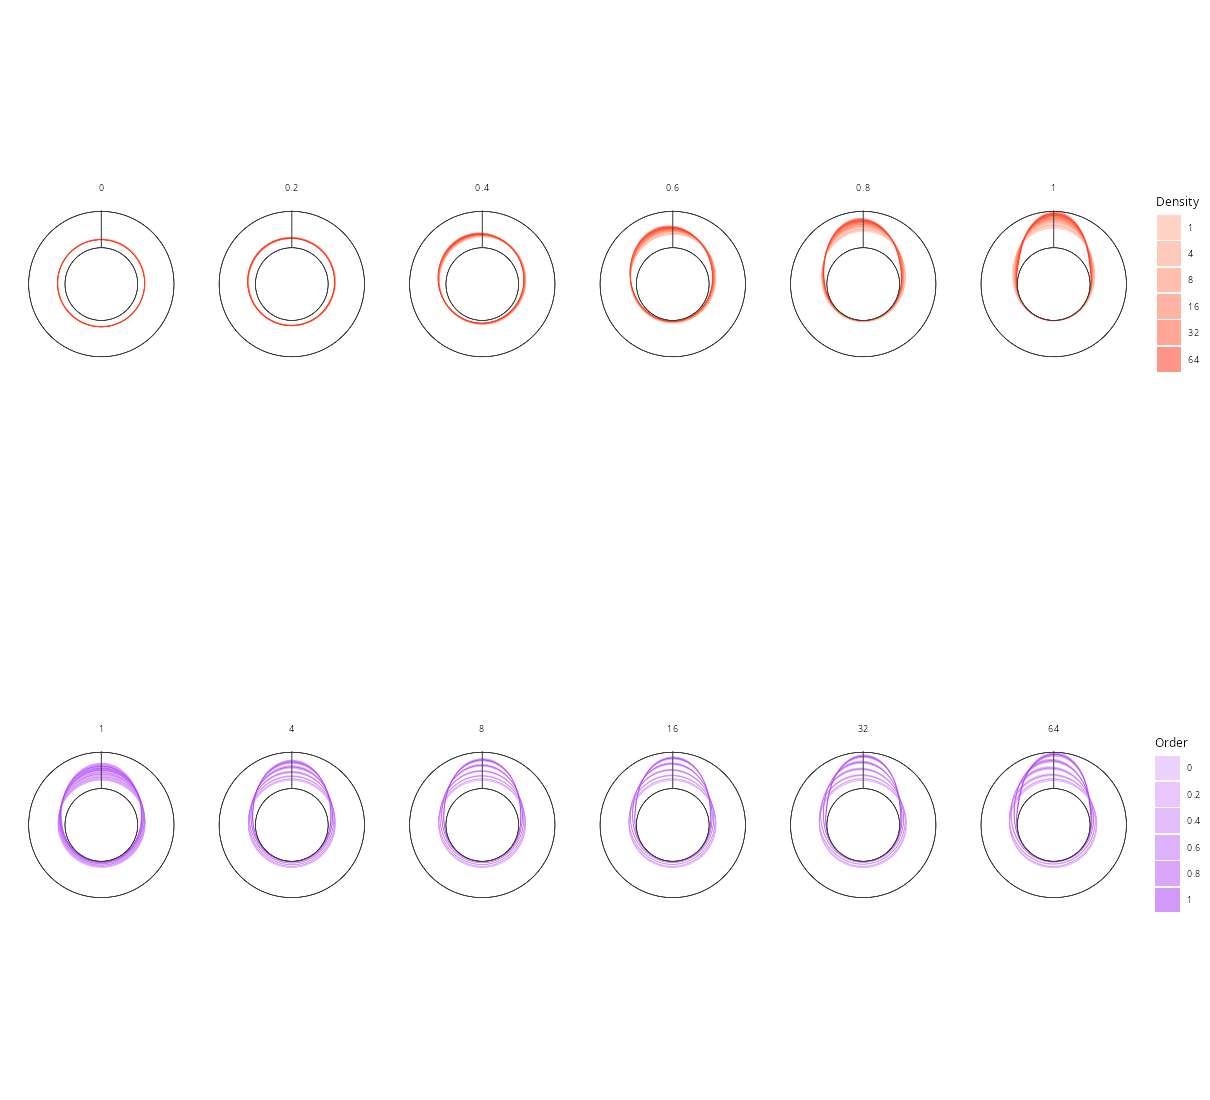

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'μ' in 'mbcsToSbcs': for μ (U+03BC)”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'κ' in 'mbcsToSbcs': for κ (U+03BA)”


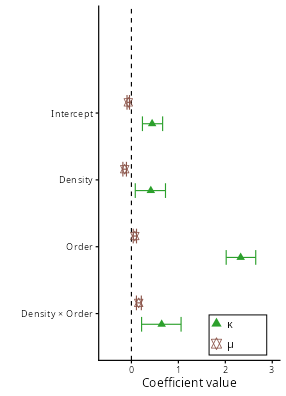

In [21]:
cell_grid <- expand.grid(order = order_levels, density = density_levels)
cell_grid$t_order <- 2 * cell_grid$order - 1
cell_grid$t_density <- 2 * log2(cell_grid$density) / log2(64) - 1
cell_grid$animal_id <- data$animal_id[1]
m_cell <- mod_circular(posterior_linpred(fit, newdata = cell_grid,
  dpar = "mu", transform = FALSE, re_formula = NA))
k_cell <- posterior_linpred(fit, newdata = cell_grid,
  dpar = "kappa", transform = TRUE, re_formula = NA)
theta <- seq(-pi, pi, length.out = 900)
pdf_summary <- do.call(rbind, lapply(seq_len(nrow(cell_grid)), function(j) {
  do.call(rbind, lapply(theta, function(t) {
    p <- exp(vm_logpdf(t, m_cell[, j], k_cell[, j]))
    data.frame(order = cell_grid$order[j], density = cell_grid$density[j],
      theta = t %% (2 * pi), median = median(p), as.list(hdi(p, 0.9)))
  }))
}))
# Two-row polar grid following the Python twin (locust_density_plots.py,
# plot_polar_pdfs): row 1 facets by order (curves = density levels, red
# shades), row 2 facets by density (curves = order levels, purple
# shades). The radius is 1 + pdf/peak_max, where peak_max is the shared
# peak of every cell's 90% HDI upper curve, so density zero sits on the
# ring at radius 1 and the shared peak on the ring at radius 2. The twin
# uses the mathematical orientation (0 at 3 o'clock,
# counter-clockwise) and no tick labels; the rings and a 0-degree spoke
# are drawn explicitly.
peak_max <- max(pdf_summary$high)
pdf_summary$r_med <- 1 + pdf_summary$median / peak_max
pdf_summary$r_low <- 1 + pdf_summary$low / peak_max
pdf_summary$r_high <- 1 + pdf_summary$high / peak_max
RMAX_polar <- 1 + 1.03
order_levels <- sort(unique(pdf_summary$order))
density_levels <- sort(unique(pdf_summary$density))
order_colors <- setNames(
  scales::colour_ramp(c("white", "purple"))(
    seq(0.45, 0.95, length.out = length(order_levels))),
  as.character(order_levels))
density_colors <- setNames(
  scales::colour_ramp(c("white", "red"))(
    seq(0.45, 0.95, length.out = length(density_levels))),
  as.character(density_levels))
polar_rings <- rbind(
  data.frame(theta = theta %% (2 * pi), y = 1, ring = 1),
  data.frame(theta = theta %% (2 * pi), y = 2, ring = 2))
polar_deco <- function(p) {
  p + geom_path(data = polar_rings, inherit.aes = FALSE,
    aes(x = theta, y = y, group = ring),
    colour = "grey25", linewidth = 0.2) +
    geom_segment(data = data.frame(x = 0, xend = 0, y = 1,
      yend = RMAX_polar), inherit.aes = FALSE,
    aes(x = x, xend = xend, y = y, yend = yend),
    colour = "grey20", linewidth = 0.3) +
    scale_x_continuous(limits = c(0, 2 * pi), expand = c(0, 0),
      breaks = NULL) +
    scale_y_continuous(limits = c(0, RMAX_polar), expand = c(0, 0),
      breaks = NULL) +
    coord_polar(start = -pi / 2, direction = -1)
}
p_row_orders <- polar_deco(ggplot(pdf_summary,
  aes(theta, r_med,
    colour = as.factor(density), group = as.factor(density))) +
  geom_ribbon(aes(ymin = r_low, ymax = r_high, fill = as.factor(density)),
    alpha = 0.5, colour = NA) +
  geom_line(linewidth = 0.2) +
  facet_wrap(~ as.factor(order), ncol = length(order_levels)) +
  scale_colour_manual(values = density_colors) +
  scale_fill_manual(values = density_colors, name = "Density") +
  theme_void(base_size = 8) + theme(legend.position = "right") +
  guides(colour = "none"))
p_row_density <- polar_deco(ggplot(pdf_summary,
  aes(theta, r_med,
    colour = as.factor(order), group = as.factor(order))) +
  geom_ribbon(aes(ymin = r_low, ymax = r_high, fill = as.factor(order)),
    alpha = 0.5, colour = NA) +
  geom_line(linewidth = 0.2) +
  facet_wrap(~ as.factor(density), ncol = length(order_levels)) +
  scale_colour_manual(values = order_colors) +
  scale_fill_manual(values = order_colors, name = "Order") +
  theme_void(base_size = 8) + theme(legend.position = "right") +
  guides(colour = "none"))
p_polar <- patchwork::wrap_plots(p_row_orders, p_row_density, ncol = 1)
save_figure(p_polar, "order_density_polar_pdfs_grid", 11, 10)

coefficient_draws <- as.data.frame(posterior::as_draws_df(fit))
mu_pars <- trace_parameters[!grepl("b_kappa_", trace_parameters)]
k_pars <- paste0("b_kappa_", sub("^b_", "", mu_pars))
coef_label <- c("Intercept", "Density", "Order", "Density \u00d7 Order")
stopifnot(length(mu_pars) == 4L, all(grepl("b_kappa_", k_pars)))
cs <- do.call(rbind, lapply(seq_along(mu_pars), function(j) {
  rbind(data.frame(term = j, comp = "mu",
    as.list(interval_row(coefficient_draws[[mu_pars[j]]],
      angular = mu_pars[j] == "b_Intercept"))),
    data.frame(term = j, comp = "kappa",
      as.list(interval_row(coefficient_draws[[k_pars[j]]]))))
}))
cs$ypos <- cs$term + ifelse(cs$comp == "kappa", 0.16, -0.16)
rng_x <- range(c(cs$low, cs$high))
pad_x <- 0.12 * diff(rng_x)
x_lo_c <- rng_x[1] - pad_x
x_hi_c <- rng_x[2] + pad_x
cspan_c <- x_hi_c - x_lo_c
p_coefficients <- ggplot(cs, aes(mean, ypos, colour = comp)) +
  geom_vline(xintercept = 0, linetype = "dashed", linewidth = 0.35) +
  geom_errorbar(aes(xmin = low, xmax = high), width = 0.22,
    linewidth = 0.35) +
  geom_point(aes(shape = comp), size = 1.7) +
  scale_colour_manual(values = c(mu = "#8C564B", kappa = "#2CA02C"),
    guide = "none") +
  scale_shape_manual(values = c(mu = 18, kappa = 17), guide = "none") +
  scale_x_continuous(limits = c(x_lo_c, x_hi_c)) +
  scale_y_reverse(limits = c(4.7, -0.6), breaks = 1:4,
    labels = coef_label, expand = c(0, 0)) +
  # Framed upper-right legend, drawn by hand (this ggplot2 build drops
  # "upperleft"/"bottomright" positions without an error).
  annotate("rect", xmin = x_lo_c + 0.62 * cspan_c,
    xmax = x_lo_c + 0.97 * cspan_c, ymin = -0.5, ymax = 0.1,
    fill = "white", colour = "black", linewidth = 0.3) +
  annotate("point", x = x_lo_c + 0.665 * cspan_c, y = -0.35, shape = 18,
    colour = "#8C564B", size = 2.1) +
  annotate("text", x = x_lo_c + 0.73 * cspan_c, y = -0.35, label = "\u03bc",
    hjust = 0, vjust = 0.5, size = 2.6) +
  annotate("point", x = x_lo_c + 0.665 * cspan_c, y = -0.05, shape = 17,
    colour = "#2CA02C", size = 2.1) +
  annotate("text", x = x_lo_c + 0.73 * cspan_c, y = -0.05, label = "\u03ba",
    hjust = 0, vjust = 0.5, size = 2.6) +
  labs(x = "Coefficient value", y = "") +
  theme_classic(base_size = 8)
save_figure(p_coefficients, "order_density_coefficients", 2.6, 3.6)


## 6. Cell-level and individual posterior predictive checks

The alignment statistic is $\overline{\cos\theta}$: the mean heading's
projection onto the zero reference direction.
Within each observed order-density cell, the empirical hierarchical
bootstrap resamples animals, then steps within animals, weighting
animals equally. Conditional predictive replicates use each animal's
fitted concentration effect and the original number of steps. Apply the
same bootstrap to replicated datasets. Individual panels compare a
within-animal step bootstrap with predictive replicates. Plot 95% HDIs.


The model verdict in one figure. Left: the matched-model sweep as delta-ELPD
relative to the best model (blue circles include order, orange squares
exclude it; the dashed line is zero). Right: the fixed effects that carry
that advantage (diamonds = mean-direction terms, triangles = concentration
terms, with 95% HDIs). Both panels share the inverted row order, so the
strongest evidence sits on top.


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'μ' in 'mbcsToSbcs': for μ (U+03BC)”


Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'κ' in 'mbcsToSbcs': for κ (U+03BA)”


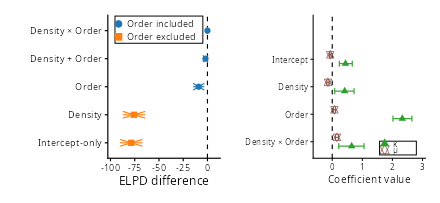

In [22]:
# Combined selection + coefficient figure: the sweep forest (left) beside
# the coefficient posteriors (right); both halves reuse the objects built
# above and share the inverted row order.
rng_cc <- range(c(cs$low, cs$high))
span_cc <- diff(rng_cc)
x_lo_cc <- rng_cc[1] - 0.10 * span_cc
x_hi_cc <- rng_cc[2] + 0.10 * span_cc
cc_span <- x_hi_cc - x_lo_cc
p_coef_comp <- ggplot(cs, aes(mean, ypos, colour = comp)) +
  geom_vline(xintercept = 0, linetype = "dashed", linewidth = 0.35) +
  geom_errorbar(aes(xmin = low, xmax = high), width = 0.22,
    linewidth = 0.35) +
  geom_point(aes(shape = comp), size = 1.5) +
  scale_colour_manual(values = c(mu = "#8C564B", kappa = "#2CA02C"),
    guide = "none") +
  scale_shape_manual(values = c(mu = 18, kappa = 17), guide = "none") +
  scale_x_continuous(limits = c(x_lo_cc, x_hi_cc)) +
  scale_y_reverse(limits = c(4.6, -0.6), breaks = 1:4,
    labels = coef_label, expand = c(0, 0)) +
  annotate("rect", xmin = x_lo_cc + 0.60 * cc_span,
    xmax = x_lo_cc + 0.96 * cc_span, ymin = -0.5, ymax = 0.1,
    fill = "white", colour = "black", linewidth = 0.3) +
  annotate("point", x = x_lo_cc + 0.65 * cc_span, y = -0.35, shape = 18,
    colour = "#8C564B", size = 1.9) +
  annotate("text", x = x_lo_cc + 0.73 * cc_span, y = -0.35, label = "\u03bc",
    hjust = 0, vjust = 0.5, size = 2.0) +
  annotate("point", x = x_lo_cc + 0.65 * cc_span, y = -0.05, shape = 17,
    colour = "#2CA02C", size = 1.9) +
  annotate("text", x = x_lo_cc + 0.73 * cc_span, y = -0.05, label = "\u03ba",
    hjust = 0, vjust = 0.5, size = 2.0) +
  labs(x = "Coefficient value", y = "") +
  theme_classic(base_size = 7)
p_composite <- patchwork::wrap_plots(p_selection, p_coef_comp, ncol = 2)
save_figure(p_composite,
  "order_density_model_selection_and_coefficients", 4.0, 1.85)


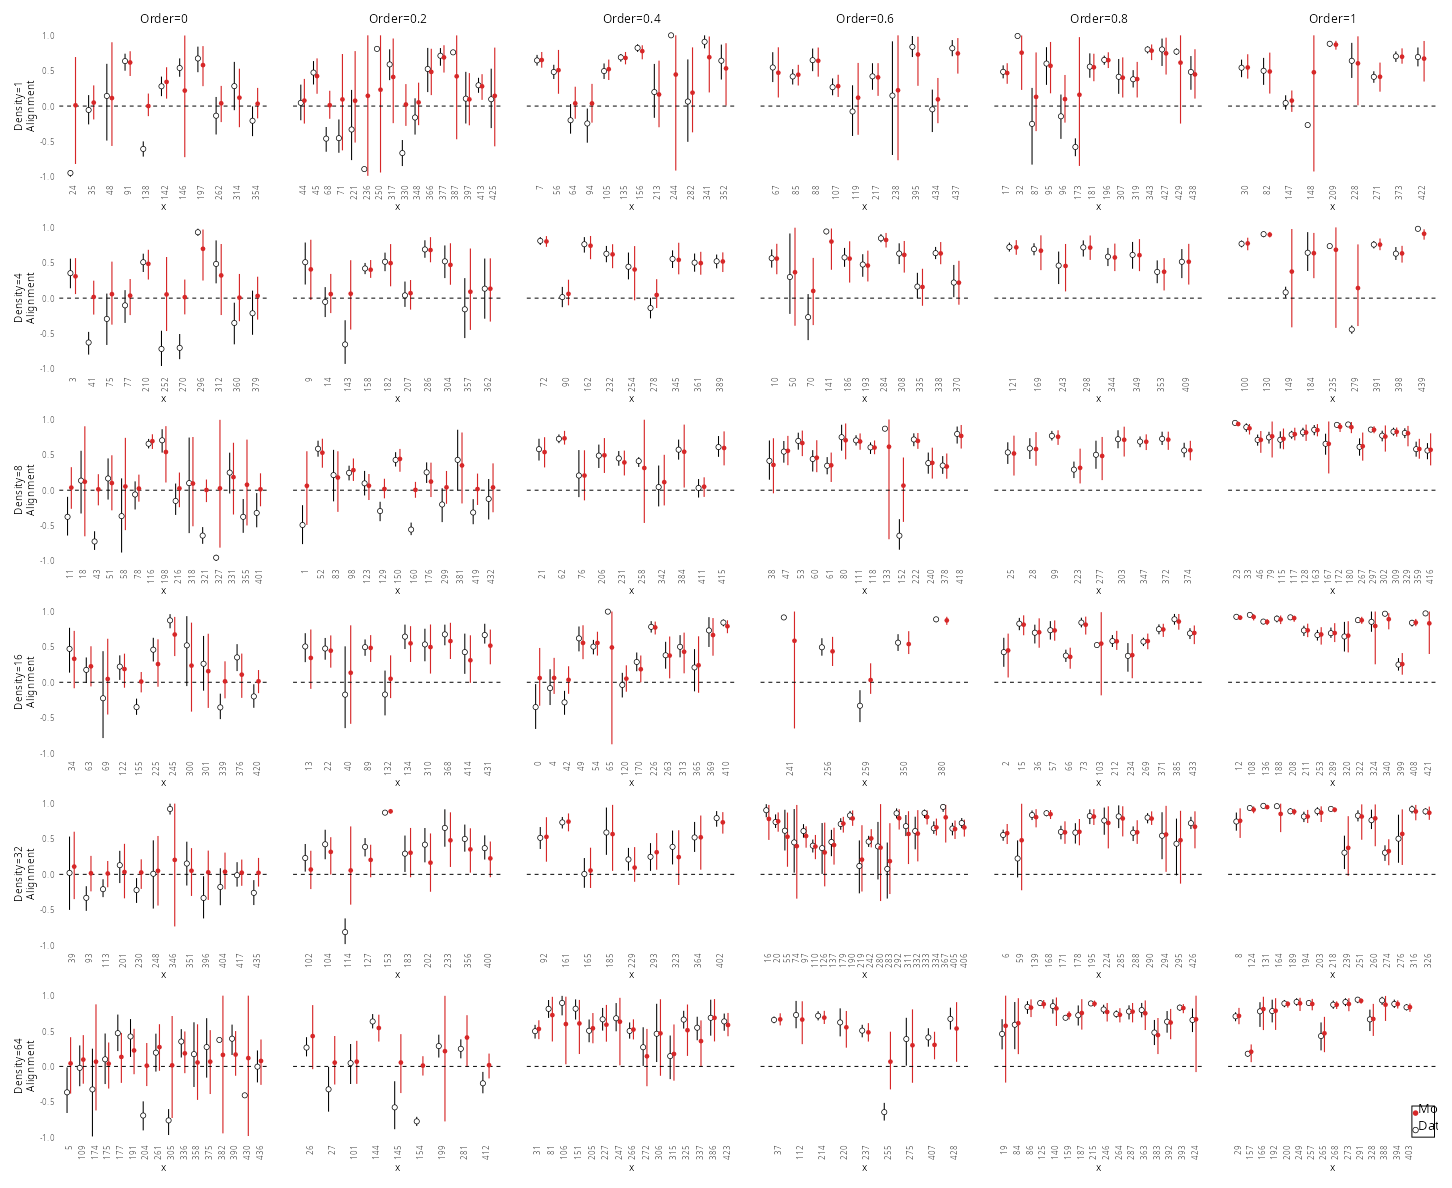

In [23]:
set.seed(SEED + 30L)
B_DATA <- if (quick_run) 150L else 1000L
B_MODEL <- if (quick_run) 100L else 600L
B_INDIV <- if (quick_run) 150L else 800L
N_REPLICATES <- if (quick_run) 100L else 400L
draw_ids <- sample.int(posterior::ndraws(posterior::as_draws_array(fit)), N_REPLICATES)
# Subset before allocating draw x observation matrices (~18,641 columns).
mu_obs <- mod_circular(posterior_linpred(fit, dpar = "mu", transform = FALSE, draw_ids = draw_ids))
k_obs <- posterior_linpred(fit, dpar = "kappa", transform = TRUE, draw_ids = draw_ids)
yrep <- simulate_angles(mu_obs, k_obs)
animal_rows <- split(seq_len(nrow(data)), data$animal_id)
animal_metadata <- data[vapply(animal_rows, function(ii) ii[1], integer(1)),
                        c("animal_id", "order", "density")]
individual_ppc <- do.call(rbind, lapply(seq_along(animal_rows), function(j) {
  ii <- animal_rows[[j]]
  y <- data$y[ii]
  empirical <- replicate(B_INDIV, mean(cos(y[sample.int(length(y), length(y), replace = TRUE)])))
  predictive <- rowMeans(cos(yrep[, ii, drop = FALSE]))
  rbind(data.frame(animal_metadata[j, ], source = "data bootstrap",
    as.list(interval_row(empirical))),
    data.frame(animal_metadata[j, ], source = "posterior predictive",
    as.list(interval_row(predictive))))
}))
# Python twin: 36-panel individual PPC (rows = density low top -> high
# bottom, columns = order). Per animal: the within-animal data bootstrap
# (open black marker + black CI) sits left of the individual-level
# posterior predictive (filled red marker + red CI); dashed zero,
# animal ids along x at 90 degrees, shared y on [-1.05, 1.05] with
# ticks every 0.5, "Model/Data" legend on the bottom-right panel.
dens_levels_ppc <- sort(unique(individual_ppc$density))
order_levels_ppc <- sort(unique(individual_ppc$order))
nrows_ppc <- length(dens_levels_ppc)
ncols_ppc <- length(order_levels_ppc)
model_red <- "#D62728"
fmt_num <- function(v) format(v, digits = 15, trim = TRUE)
ppc_panel <- function(sub, show_y, top_row, left_col, last_panel, o, d) {
  sub <- sub[order(as.character(sub$animal_id)), , drop = FALSE]
  aids <- unique(sub$animal_id)
  n_an <- length(aids)
  xpos <- match(sub$animal_id, aids) +
    ifelse(sub$source == "data bootstrap", -0.14, 0.14)
  pdata <- data.frame(x = xpos[sub$source == "data bootstrap"],
    y = sub$mean[sub$source == "data bootstrap"],
    low = sub$low[sub$source == "data bootstrap"],
    high = sub$high[sub$source == "data bootstrap"])
  pmodel <- data.frame(x = xpos[sub$source == "posterior predictive"],
    y = sub$mean[sub$source == "posterior predictive"],
    low = sub$low[sub$source == "posterior predictive"],
    high = sub$high[sub$source == "posterior predictive"])
  p <- ggplot() +
    geom_segment(data = pdata, inherit.aes = FALSE,
      aes(x = x, y = y, xend = x, yend = low),
      colour = "black", linewidth = 0.32) +
    geom_segment(data = pdata, inherit.aes = FALSE,
      aes(x = x, y = y, xend = x, yend = high),
      colour = "black", linewidth = 0.32) +
    geom_segment(data = pmodel, inherit.aes = FALSE,
      aes(x = x, y = y, xend = x, yend = low),
      colour = model_red, linewidth = 0.35) +
    geom_segment(data = pmodel, inherit.aes = FALSE,
      aes(x = x, y = y, xend = x, yend = high),
      colour = model_red, linewidth = 0.35) +
    geom_hline(yintercept = 0, linetype = "dashed", linewidth = 0.3) +
    geom_point(data = pdata, inherit.aes = FALSE, aes(x = x, y = y),
      shape = 21, colour = "black", fill = "white", size = 1.4) +
    geom_point(data = pmodel, inherit.aes = FALSE, aes(x = x, y = y),
      shape = 16, colour = model_red, size = 1.3) +
    scale_x_continuous(
      limits = c(0.25, n_an + if (last_panel) 2.4 else 0.75),
      breaks = seq_len(n_an), labels = aids, expand = c(0, 0)) +
    scale_y_continuous(limits = c(-1.05, 1.05), expand = c(0, 0),
      breaks = seq(-1, 1, by = 0.5)) +
    labs(x = NULL, y = if (left_col) paste0("Density=", fmt_num(d),
      "\nAlignment") else "") +
    theme_classic(base_size = 7) +
    theme(axis.text.x = element_text(size = 5.5, angle = 90, hjust = 1,
      vjust = 0.5),
      axis.title.y = element_text(size = 7),
      panel.grid.major = element_blank(),
      panel.grid.minor = element_blank())
  if (!show_y) {
    p <- p + theme(axis.text.y = element_blank(),
      axis.ticks.y = element_blank())
  }
  if (top_row) {
    p <- p + labs(title = paste0("Order=", fmt_num(o))) +
      theme(plot.title = element_text(size = 8, hjust = 0.5))
  }
  if (last_panel) {
    lg_x <- n_an + 0.30
    p <- p +
      annotate("rect", xmin = lg_x, xmax = lg_x + 1.85,
        ymin = -1.00, ymax = -0.56,
        fill = "white", colour = "black", linewidth = 0.3) +
      annotate("point", x = lg_x + 0.30, y = -0.66, shape = 16,
        colour = model_red, size = 1.5) +
      annotate("text", x = lg_x + 0.50, y = -0.66, hjust = 0,
        vjust = 0, size = 3, colour = "black", label = "Model") +
      annotate("point", x = lg_x + 0.30, y = -0.90, shape = 21,
        colour = "black", fill = "white", size = 1.5) +
      annotate("text", x = lg_x + 0.50, y = -0.90, hjust = 0,
        vjust = 0, size = 3, colour = "black", label = "Data")
  }
  p
}
ppc_panels <- list()
for (ri in seq_len(nrows_ppc)) {
  for (ci in seq_len(ncols_ppc)) {
    d <- dens_levels_ppc[ri]
    o <- order_levels_ppc[ci]
    sub <- individual_ppc[individual_ppc$density == d &
      individual_ppc$order == o, , drop = FALSE]
    ppc_panels[[length(ppc_panels) + 1L]] <- ppc_panel(
      sub, show_y = (ci == 1L), top_row = (ri == 1L),
      left_col = (ci == 1L),
      last_panel = (ri == nrows_ppc && ci == ncols_ppc), o, d)
  }
}
p_individual_ppc <- do.call(patchwork::wrap_plots,
  c(ppc_panels, list(ncol = ncols_ppc)))
save_figure(p_individual_ppc, "order_density_individual_cell_ppc",
  max(6.8, 2.2 * ncols_ppc), max(3.2, 1.8 * nrows_ppc))

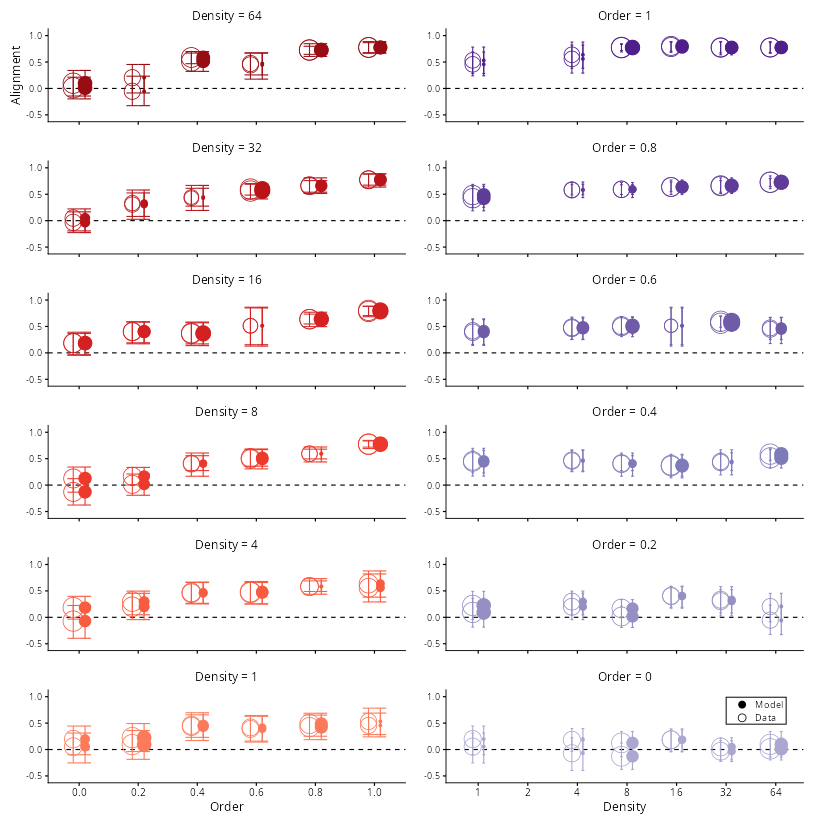

In [24]:
cell_rows <- split(seq_len(nrow(animal_metadata)),
  interaction(animal_metadata$order, animal_metadata$density, drop = TRUE))
cell_ppc <- do.call(rbind, lapply(cell_rows, function(animals) {
  empirical <- replicate(B_DATA, {
    selected <- animals[sample.int(length(animals), length(animals), replace = TRUE)]
    mean(vapply(selected, function(j) {
      y <- data$y[animal_rows[[j]]]
      mean(cos(y[sample.int(length(y), length(y), replace = TRUE)]))
    }, numeric(1)))
  })
  predictive <- replicate(B_MODEL, {
    d <- sample.int(nrow(yrep), 1)
    selected <- animals[sample.int(length(animals), length(animals), replace = TRUE)]
    mean(vapply(selected, function(j) {
      y <- yrep[d, animal_rows[[j]]]
      mean(cos(y[sample.int(length(y), length(y), replace = TRUE)]))
    }, numeric(1)))
  })
  g <- animal_metadata[animals[1], c("order", "density")]
  rbind(data.frame(g, source = "data bootstrap", n_an = length(animals),
    as.list(interval_row(empirical))),
    data.frame(g, source = "posterior predictive", n_an = length(animals),
    as.list(interval_row(predictive))))
}))

# 2 columns x 6 panels, one row per condition: the left column walks
# x = order inside each density row (reds, densest = darkest) and the right
# column walks x = density (log 2) inside each order row (purples, most
# ordered = darkest). Open markers = the data bootstrap, filled markers =
# the posterior predictive; marker size grows with the animal count in the
# cell; the dashed line is zero alignment. This build drops a labs call
# bundled into a theme object when the composite is added to a plot, so the
# per-panel labels are attached to the plot itself.
dens_row <- rev(sort(unique(cell_ppc$density)))
order_row <- rev(sort(unique(cell_ppc$order)))
dens_reds <- c("64" = "#980C13", "32" = "#B81419", "16" = "#D32020",
  "8" = "#ED392B", "4" = "#F75B40", "1" = "#FB7A5A")
order_purples <- c("1" = "#4F1F8B", "0.8" = "#5F3C99", "0.6" = "#6F5BA8",
  "0.4" = "#7F7BB9", "0.2" = "#9490C3", "0" = "#AAA8D0")
msize <- function(n) (2.6 + 0.12 * sqrt(n)) * 25.4 / 72.27
pcc_thm <- function(bottom) {
  theme_classic(base_size = 8) +
    theme(axis.line = element_line(colour = "black", linewidth = 0.28),
      panel.grid = element_blank(),
      axis.text.x = if (bottom) element_text(size = 7) else element_blank(),
      plot.title = element_text(size = 8, hjust = 0.5),
      plot.margin = margin(1, 1, 1, 1, "pt"))
}
p_cell_left <- lapply(seq_along(dens_row), function(r) {
  d <- as.character(dens_row[r])
  sub <- cell_ppc[cell_ppc$density == dens_row[r], , drop = FALSE]
  sub$xd <- sub$order - 0.02
  sub$xm <- sub$order + 0.02
  sub$col <- dens_reds[d]
  p <- ggplot(sub, aes(mean, mean, colour = col)) +
    geom_hline(yintercept = 0, linetype = "dashed", linewidth = 0.35) +
    geom_segment(data = sub[sub$source == "data bootstrap", , drop = FALSE],
      aes(x = xd, y = mean, xend = xd, yend = low),
      linewidth = 0.32) +
    geom_segment(data = sub[sub$source == "data bootstrap", , drop = FALSE],
      aes(x = xd, y = mean, xend = xd, yend = high),
      linewidth = 0.32) +
    geom_segment(data = sub[sub$source == "data bootstrap", , drop = FALSE],
      aes(x = xd - 0.02, y = low, xend = xd + 0.02, yend = low),
      linewidth = 0.32) +
    geom_segment(data = sub[sub$source == "data bootstrap", , drop = FALSE],
      aes(x = xd - 0.02, y = high, xend = xd + 0.02, yend = high),
      linewidth = 0.32) +
    geom_point(data = sub[sub$source == "data bootstrap", , drop = FALSE],
      aes(x = xd, size = msize(n_an)), shape = 1, fill = "white") +
    geom_segment(data = sub[sub$source == "posterior predictive", , drop = FALSE],
      aes(x = xm, y = mean, xend = xm, yend = low),
      linewidth = 0.35) +
    geom_segment(data = sub[sub$source == "posterior predictive", , drop = FALSE],
      aes(x = xm, y = mean, xend = xm, yend = high),
      linewidth = 0.35) +
    geom_segment(data = sub[sub$source == "posterior predictive", , drop = FALSE],
      aes(x = xm - 0.02, y = low, xend = xm + 0.02, yend = low),
      linewidth = 0.35) +
    geom_segment(data = sub[sub$source == "posterior predictive", , drop = FALSE],
      aes(x = xm - 0.02, y = high, xend = xm + 0.02, yend = high),
      linewidth = 0.35) +
    geom_point(data = sub[sub$source == "posterior predictive", , drop = FALSE],
      aes(x = xm, size = msize(n_an) * sqrt(0.9)), shape = 16) +
    scale_colour_identity(guide = "none") +
    scale_x_continuous(limits = c(-0.05, 1.05),
      breaks = seq(0, 1, by = 0.2),
      labels = format(seq(0, 1, by = 0.2), nsmall = 1)) +
    scale_y_continuous(limits = c(-0.55, 1.05), breaks = c(-0.5, 0, 0.5, 1)) +
    pcc_thm(r == length(dens_row)) +
    labs(title = paste0("Density = ", d),
      x = if (r == length(dens_row)) "Order" else "",
      y = if (r == 1L) "Alignment" else "") +
    scale_size_identity(guide = "none")
  p
})
p_cell_right <- lapply(seq_along(order_row), function(r) {
  o <- order_row[r]
  sub <- cell_ppc[cell_ppc$order == o, , drop = FALSE]
  sub$xd <- sub$density / 1.08
  sub$xm <- sub$density * 1.08
  sub$col <- order_purples[format(o, nsmall = 0)]
  p <- ggplot(sub, aes(mean, mean, colour = col)) +
    geom_hline(yintercept = 0, linetype = "dashed", linewidth = 0.35) +
    geom_segment(data = sub[sub$source == "data bootstrap", , drop = FALSE],
      aes(x = xd, y = mean, xend = xd, yend = low),
      linewidth = 0.32) +
    geom_segment(data = sub[sub$source == "data bootstrap", , drop = FALSE],
      aes(x = xd, y = mean, xend = xd, yend = high),
      linewidth = 0.32) +
    geom_segment(data = sub[sub$source == "data bootstrap", , drop = FALSE],
      aes(x = xd / 1.02, y = low, xend = xd * 1.02, yend = low),
      linewidth = 0.32) +
    geom_segment(data = sub[sub$source == "data bootstrap", , drop = FALSE],
      aes(x = xd / 1.02, y = high, xend = xd * 1.02, yend = high),
      linewidth = 0.32) +
    geom_point(data = sub[sub$source == "data bootstrap", , drop = FALSE],
      aes(x = xd, size = msize(n_an)), shape = 1, fill = "white") +
    geom_segment(data = sub[sub$source == "posterior predictive", , drop = FALSE],
      aes(x = xm, y = mean, xend = xm, yend = high),
      linewidth = 0.35) +
    geom_segment(data = sub[sub$source == "posterior predictive", , drop = FALSE],
      aes(x = xm, y = mean, xend = xm, yend = low),
      linewidth = 0.35) +
    geom_segment(data = sub[sub$source == "posterior predictive", , drop = FALSE],
      aes(x = xm / 1.02, y = high, xend = xm * 1.02, yend = high),
      linewidth = 0.35) +
    geom_segment(data = sub[sub$source == "posterior predictive", , drop = FALSE],
      aes(x = xm / 1.02, y = low, xend = xm * 1.02, yend = low),
      linewidth = 0.35) +
    geom_point(data = sub[sub$source == "posterior predictive", , drop = FALSE],
      aes(x = xm, size = msize(n_an) * sqrt(0.9)), shape = 16) +
    scale_colour_identity(guide = "none") +
    scale_x_continuous(
      transform = scales::trans_new("log2", log2, function(x) 2 ^ x),
      limits = c(0.8, 75), breaks = c(1, 2, 4, 8, 16, 32, 64)) +
    scale_y_continuous(limits = c(-0.55, 1.05), breaks = c(-0.5, 0, 0.5, 1)) +
    pcc_thm(r == length(order_row)) +
    labs(title = paste0("Order = ", format(o, nsmall = 0)),
      x = if (r == length(order_row)) "Density" else "",
      y = "") +
    scale_size_identity(guide = "none")
  if (r == length(order_row)) {
    # framed Model/Data legend in the bottom-right panel, drawn by hand in
    # data coordinates (legend positions in corners are dropped silently
    # by this ggplot2 build).
    p <- p +
      annotate("rect", xmin = 32, xmax = 74, ymin = 0.48, ymax = 0.99,
        fill = "white", colour = "black", linewidth = 0.3) +
      annotate("point", x = 40, y = 0.85, shape = 16, colour = "black",
        size = 2.2) +
      annotate("text", x = 48, y = 0.85, label = "Model", hjust = 0,
        vjust = 0.5, size = 2.2) +
      annotate("point", x = 40, y = 0.60, shape = 1, colour = "black",
        fill = "white", size = 2.2) +
      annotate("text", x = 48, y = 0.60, label = "Data", hjust = 0,
        vjust = 0.5, size = 2.2)
  }
  p
})
p_cell_ppc <- patchwork::wrap_plots(
  patchwork::wrap_plots(p_cell_left, ncol = 1),
  patchwork::wrap_plots(p_cell_right, ncol = 1),
  ncol = 2)
save_figure(p_cell_ppc, "order_density_cell_ppc_dots", 7.4, 7.5)


## Limitations

Review Pareto k before trusting PSIS-LOO differences; use refitting
or a more appropriate validation design if influential animals make
the approximation unreliable. Step-level conditional LOO does not
measure performance on new animals. The fitted interaction is the
final specification for this analysis.

See the [model guide](../models.md), [circular GLMM guide](../math/glmms.md),
and [R setup](../getting-started-r.md) for the statistical framework and
environment.